# Определение авторства с использованием сжатия

Воспроизведение результатов статьи:
> Ryabko, B.; Savina, N. Using Data Compression to Build a Method for Statistically Verified Attribution of Literary Texts. Entropy 2021, 23, 1302.

## Цели проекта
- **(a)** Воспроизвести результаты статьи
- **(b)** Исследовать влияние выбора метода сжатия (включая нейросетевые)
- **(c)** Рассмотреть задачу выбора лучшего перевода для данного автора

In [1]:
# import sys
# sys.path.insert(0, 'src')

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.theory import phi, phi_authors, build_table, chi_square, significance_level, get_accuracy
from src.preprocessing import run_data_pipeline, split_into_slices
from src.data_pipeline import process

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

## 1. Подготовка данных

### 1.1 Списки авторов

In [4]:
# Авторы 1915-1940 годов (Таблица 1 в статье)
AUTHORS_1915_1940 = [
    'Pasternak', 'Nabokov', 'Paustovsky', 'Veresayev', 'Zamyatin',
    'Bunin', 'Gorky', 'Kuprin', 'Platonov', 'Mandelstam',
    'Olesha', 'Katayev', 'Green', 'Zhitkov', 'Ehrenburg',
    'Tynyanov', 'Gaidar'
]

# Авторы для задачи атрибуции Ильф/Петров vs Булгаков (Таблицы 3-5)
AUTHORS_BULGAKOV = ['Bulgakov', 'Ilf_and_Petrov']

# Авторы 19 века (Таблица 6)
AUTHORS_19_CENTURY = [
    'Nekrasov', 'Panaeva', 'Turgenev', 'Goncharov', 'Gogol', 'Dahl',
    'Dostoevsky', 'Panaev', 'SShchedrin', 'Tolstoy', 'Druzhinin'
]

# Типы предобработки
PREPROCESS_TYPES = [
    'lower_nopunct_nostop',
    'lower_nopunct_withstop',
    'origcase_nopunct_nostop',
    'origcase_nopunct_withstop',
    'lower_withpunct_nostop',
    'origcase_withpunct_nostop',
    'lower_withpunct_withstop',
    'origcase_withpunct_withstop'
]

# Компрессоры
COMPRESSORS = ['gzip', 'bzip2', 'lzma', 'zstd', 'brotli', 'paq']

### 1.2 Генерация датасетов

In [5]:
TRAIN_KB = 64
TEST_KB = 64
N_SLICES = 16

# # Раскомментируйте для генерации данных:
# run_data_pipeline(AUTHORS_1915_1940, train_kb=TRAIN_KB, test_kb=TEST_KB)
# split_into_slices(AUTHORS_1915_1940, n_slices=N_SLICES)

---
## 2. Эксперимент 1: Таблица 1 (17 авторов 1915-1940)

In [31]:
def run_experiment(authors, preprocess_type, n_slices, compressor, lvl=6):
    table = build_table(authors, preprocess_type, n_slices, compressor, lvl)
    chi2, p_value, df = significance_level(table)
    accuracy = get_accuracy(table)
    return {
        'table': table,
        'chi2': chi2,
        'p_value': p_value,
        'df': df,
        'accuracy': accuracy
    }

In [5]:
result = run_experiment(
    authors=AUTHORS_1915_1940,
    preprocess_type='origcase_nopunct_withstop',
    n_slices=16,
    compressor='lzma',
    lvl=6
)
print(f"chi2 = {result['chi2']:.1f}, p-value = {result['p_value']:.2e}, Accuracy = {result['accuracy']:.2%}")
result['table']

chi2 = 1431.8, p-value = 0.00e+00, Accuracy = 48.53%


,Pasternak,Nabokov,Paustovsky,Veresayev,Zamyatin,Bunin,Gorky,Kuprin,Platonov,Mandelstam,Olesha,Katayev,Green,Zhitkov,Ehrenburg,Tynyanov,Gaidar
Pasternak,12,0,0,0,0,0,0,0,0,0,0,0,4,0,0,0,0
Nabokov,4,4,0,0,0,1,0,2,0,2,0,0,3,0,0,0,0
Paustovsky,1,1,10,0,0,0,0,0,0,1,0,0,2,0,0,0,1
Veresayev,1,0,0,1,0,1,0,8,1,1,0,0,0,0,3,0,0
Zamyatin,1,0,0,3,12,0,0,0,0,0,0,0,0,0,0,0,0
Bunin,3,2,0,1,0,3,1,6,0,0,0,0,0,0,0,0,0
Gorky,0,1,0,1,0,1,8,2,0,1,0,1,0,0,1,0,0
Kuprin,3,0,0,2,0,0,0,10,0,0,0,0,1,0,0,0,0
Platonov,2,0,0,0,0,0,3,0,11,0,0,0,0,0,0,0,0
Mandelstam,5,0,1,0,0,0,0,0,0,8,2,0,0,0,0,0,0


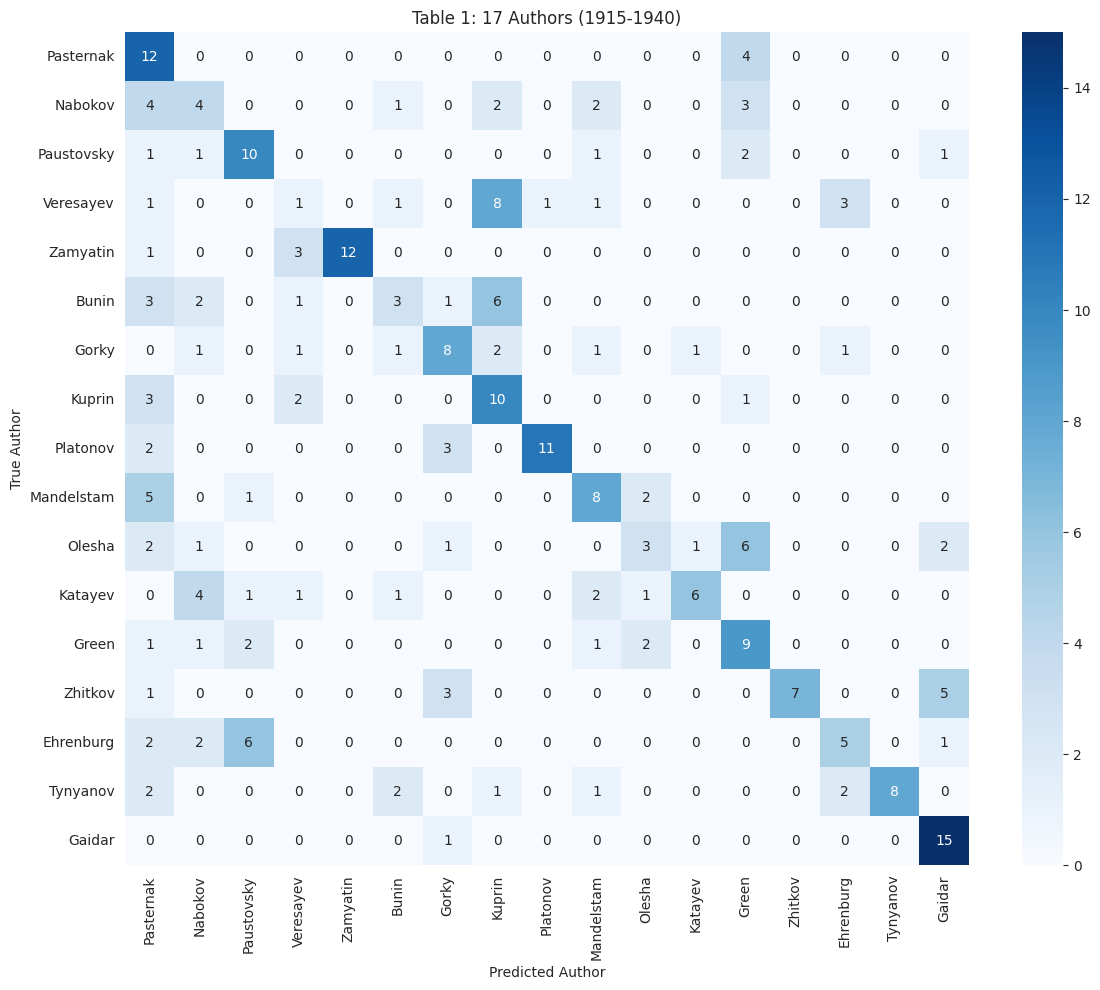

In [6]:
def plot_confusion_matrix(table, title='Confusion Matrix'):
    plt.figure(figsize=(12, 10))
    sns.heatmap(table, annot=True, fmt='d', cmap='Blues')
    plt.title(title)
    plt.xlabel('Predicted Author')
    plt.ylabel('True Author')
    plt.tight_layout()
    plt.show()

plot_confusion_matrix(result['table'], 'Table 1: 17 Authors (1915-1940)')

### 2.1 Сравнение типов предобработки (Таблица 2)

In [16]:
TRAIN_KB = 64
TEST_KB = 64
N_SLICES = 16

run_data_pipeline(AUTHORS_1915_1940, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=42)
split_into_slices(AUTHORS_1915_1940, n_slices=N_SLICES)

Генерация датасета
Для Bunin!
Готово! Сохранено в папке data/processed/Bunin/lower_nopunct_nostop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data/processed/Bunin/lower_nopunct_withstop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data/processed/Bunin/origcase_nopunct_nostop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data/processed/Bunin/origcase_nopunct_withstop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data/processed/Bunin/lower_withpunct_nostop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке da

In [8]:
def compare_preprocessing(authors, n_slices, compressor, lvl=6):
    results = []
    for preprocess_type in PREPROCESS_TYPES:
        try:
            res = run_experiment(authors, preprocess_type, n_slices, compressor, lvl)
            results.append({
                'preprocessing': preprocess_type,
                'chi2': res['chi2'],
                'accuracy': res['accuracy'],
                'p_value': res['p_value']
            })
        except FileNotFoundError as e:
            print(f"Skipping {preprocess_type}: {e}")
    return pd.DataFrame(results).sort_values('chi2', ascending=False)

preprocessing_comparison = compare_preprocessing(AUTHORS_1915_1940, 16, 'lzma')
preprocessing_comparison

,preprocessing,chi2,accuracy,p_value
6,lower_withpunct_withstop,1769.257185,0.573529,0.0
7,origcase_withpunct_withstop,1763.033107,0.566176,0.0
4,lower_withpunct_nostop,1472.733614,0.496324,0.0
5,origcase_withpunct_nostop,1455.476470,0.492647,0.0
3,origcase_nopunct_withstop,1431.788858,0.485294,0.0
1,lower_nopunct_withstop,1377.601834,0.485294,0.0
0,lower_nopunct_nostop,1255.690704,0.437500,0.0
2,origcase_nopunct_nostop,1242.625075,0.441176,0.0


### 2.2 Сравнение компрессоров

In [ ]:
def compare_compressors(authors, preprocess_type, n_slices):
    results = []
    compressor_levels = {
        'gzip': 6, 'bzip2': 6, 'lzma': 6,
        'zstd': 10, 'brotli': 6, 'paq': 1
    }
    for compressor, lvl in compressor_levels.items():
        try:
            print(f"Testing {compressor}...")
            res = run_experiment(authors, preprocess_type, n_slices, compressor, lvl)
            results.append({
                'compressor': compressor,
                'chi2': res['chi2'],
                'accuracy': res['accuracy'],
                'p_value': res['p_value']
            })
        except Exception as e:
            print(f"Error with {compressor}: {e}")
    return pd.DataFrame(results).sort_values('chi2', ascending=False)

compressor_comparison = compare_compressors(AUTHORS_1915_1940, 'origcase_withpunct_withstop', 16)
compressor_comparison

Testing gzip...


/home/platon/Documents/TI/information-theory-determining-authorship-using-compression/src/theory.py:118: RuntimeWarning: invalid value encountered in divide
  chi2_val = ((A - expected)**2 / expected).sum()


Testing bzip2...
Testing lzma...
Testing zstd...
Testing brotli...
Testing paq...


,compressor,chi2,accuracy,p_value
5,paq,1721.718516,0.547794,0.0
2,lzma,1431.788858,0.485294,0.0
3,zstd,1255.650303,0.452206,0.0
4,brotli,1207.409862,0.430147,0.0
0,gzip,NaN,0.341912,NaN
1,bzip2,NaN,0.301471,NaN


In [ ]:
present_table = compressor_comparison.copy()

# Переименовываем столбцы
present_table = present_table.rename(columns={
    'compressor': 'Компрессор',
    'chi2': 'χ²',
    'accuracy': 'Accuracy',
    'p_value': 'P-value'
})

present_table['χ²'] = present_table['χ²'].round(3)
present_table['Accuracy'] = present_table['Accuracy'].round(3)

present_table

,Компрессор,χ²,Accuracy,P-value
5,paq,2355.911,0.713,0.0
2,lzma,2039.546,0.643,0.0
3,zstd,1651.507,0.566,0.0
4,brotli,1457.457,0.537,0.0
1,bzip2,1167.252,0.460,0.0
0,gzip,932.909,0.393,0.0


In [15]:
TRAIN_KB = 64
TEST_KB = 16
N_SLICES = 4

curr_authors = AUTHORS_1915_1940[:2]

run_data_pipeline(curr_authors, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=42)
split_into_slices(curr_authors, n_slices=N_SLICES)

Генерация датасета
Для Nabokov!
Готово! Сохранено в папке data/processed/Nabokov/lower_nopunct_nostop
В train попали: ['Отчаяние', 'Король, дама. валет', 'Машенька']
В test: ['Соглядатай', 'Защита Лужина']
Готово! Сохранено в папке data/processed/Nabokov/lower_nopunct_withstop
В train попали: ['Отчаяние', 'Король, дама. валет', 'Машенька']
В test: ['Соглядатай', 'Защита Лужина']
Готово! Сохранено в папке data/processed/Nabokov/origcase_nopunct_nostop
В train попали: ['Отчаяние', 'Король, дама. валет', 'Машенька']
В test: ['Соглядатай', 'Защита Лужина']
Готово! Сохранено в папке data/processed/Nabokov/origcase_nopunct_withstop
В train попали: ['Отчаяние', 'Король, дама. валет', 'Машенька']
В test: ['Соглядатай', 'Защита Лужина']
Готово! Сохранено в папке data/processed/Nabokov/lower_withpunct_nostop
В train попали: ['Отчаяние', 'Король, дама. валет', 'Машенька']
В test: ['Соглядатай', 'Защита Лужина']
Готово! Сохранено в папке data/processed/Nabokov/origcase_withpunct_nostop
В train поп

In [ ]:
def compare_compressors(authors, preprocess_type, n_slices, compression_types):
    results = []
    compressor_levels = {
        'gzip': 5, 'bzip2': 5, 'lzma': 5,
        'zstd': 9, 'brotli': 5, 'paq': 1,
        
        'cmix': 1,'nncp': 3
    }
    for compressor, lvl in compressor_levels.items():
        if compressor in compression_types:
            try:
                print(f"Testing {compressor}...")
                res = run_experiment(authors, preprocess_type, n_slices, compressor, lvl)
                results.append({
                    'compressor': compressor,
                    'chi2': res['chi2'],
                    'accuracy': res['accuracy'],
                    'p_value': res['p_value']
                })
                # Освобождаем память после нейросетевых компрессоров
                if compressor in ('paq', 'llm', 'ts_zip'):
                    clear_model_cache()
            except Exception as e:
                print(f"Error with {compressor}: {e}")
    return pd.DataFrame(results).sort_values('chi2', ascending=False)

In [21]:
compressor_comparison = compare_compressors(curr_authors, 'origcase_withpunct_withstop', N_SLICES, compression_types=['nncp'])
compressor_comparison

Testing nncp...


,compressor,chi2,accuracy,p_value
0,nncp,0.0,0.5,1.0


In [22]:
compressor_comparison = compare_compressors(curr_authors, 'origcase_withpunct_withstop', N_SLICES, compression_types=['cmix'])
compressor_comparison

Testing cmix...


,compressor,chi2,accuracy,p_value
0,cmix,8.0,1.0,0.004678


In [23]:
compressor_comparison = compare_compressors(curr_authors, 'origcase_withpunct_withstop', N_SLICES, compression_types=['lzma'])
compressor_comparison

Testing lzma...


,compressor,chi2,accuracy,p_value
0,lzma,4.8,0.875,0.02846


In [24]:
compressor_comparison = compare_compressors(curr_authors, 'origcase_withpunct_withstop', N_SLICES, compression_types=['paq'])
compressor_comparison

Testing paq...


,compressor,chi2,accuracy,p_value
0,paq,8.0,1.0,0.004678


### 2.3 Сравнение размеров

In [ ]:
def compare_size(authors, preprocess_type, n_slices, compressor, lvl=4):
    results = []
    for size in [32, 64, 128, 256]:
        try:
            run_data_pipeline(AUTHORS_1915_1940, train_kb=size, test_kb=size, seed=42)
            split_into_slices(AUTHORS_1915_1940, n_slices=n_slices)
            res = run_experiment(authors, preprocess_type, n_slices, compressor, lvl)
            results.append({
                'size': size,
                'chi2': res['chi2'],
                'accuracy': res['accuracy'],
                'p_value': res['p_value']
            })
        except FileNotFoundError as e:
            print(f"Skipping {preprocess_type}: {e}")
    return pd.DataFrame(results).sort_values('chi2', ascending=False)

size_comparison = compare_size(AUTHORS_1915_1940, 'origcase_withpunct_withstop', 16, 'lzma')
size_comparison

Генерация датасета
Для Bunin!
Готово! Сохранено в папке data\processed\Bunin\lower_nopunct_nostop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data\processed\Bunin\lower_nopunct_withstop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data\processed\Bunin\origcase_nopunct_nostop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data\processed\Bunin\origcase_nopunct_withstop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке data\processed\Bunin\lower_withpunct_nostop
В train попали: ['Митина любовь', 'Жизнь Арсеньева', 'Легкое дыхание', 'Суходол']
В test: ['Деревня', 'Темные аллеи']
Готово! Сохранено в папке da

,size,chi2,accuracy,p_value
3,256,3814.096681,0.930147,0.0
2,128,3312.962502,0.863971,0.0
1,64,2222.315310,0.683824,0.0
0,32,1513.161979,0.511029,0.0


In [ ]:
present_table = size_comparison.copy()

# Переименовываем столбцы
present_table = present_table.rename(columns={
    'size': 'Размер',
    'chi2': 'χ²',
    'accuracy': 'Accuracy',
    'p_value': 'P-value'
})

present_table['χ²'] = present_table['χ²'].round(3)
present_table['Accuracy'] = present_table['Accuracy'].round(3)

present_table

,Размер,χ²,Accuracy,P-value
3,256,3814.097,0.930,0.0
2,128,3312.963,0.864,0.0
1,64,2222.315,0.684,0.0
0,32,1513.162,0.511,0.0


---
## 3. Эксперимент 2: Булгаков vs Ильф/Петров (Таблицы 5-6)

In [6]:
best_preprocess_type = 'origcase_withpunct_withstop'
best_compressor = 'paq'
best_size_kb = 256
exp_2_n_slices = 64

In [14]:

# exp_2_authors = ['Bulgakov', 'Bulgakov_experiment', "Ilf_and_Petrov", 'Ilf_and_Petrov_experiment']
exp_2_authors_train = ['Bulgakov', 'Ilf_and_Petrov']
run_data_pipeline(authors=exp_2_authors_train, train_kb=best_size_kb, test_kb=best_size_kb, seed=42)

Генерация датасета
Для Bulgakov!
Готово! Сохранено в папке data/processed/Bulgakov/lower_nopunct_nostop
В train попали: ['Мастер и Маргарита (отрывок)', 'Дьяволиада', 'Записки юного врача']
В test: ['Морфий', 'Белая гвардия']
Готово! Сохранено в папке data/processed/Bulgakov/lower_nopunct_withstop
В train попали: ['Мастер и Маргарита (отрывок)', 'Дьяволиада', 'Записки юного врача']
В test: ['Морфий', 'Белая гвардия']
Готово! Сохранено в папке data/processed/Bulgakov/origcase_nopunct_nostop
В train попали: ['Мастер и Маргарита (отрывок)', 'Дьяволиада', 'Записки юного врача']
В test: ['Морфий', 'Белая гвардия']
Готово! Сохранено в папке data/processed/Bulgakov/origcase_nopunct_withstop
В train попали: ['Мастер и Маргарита (отрывок)', 'Дьяволиада', 'Записки юного врача']
В test: ['Морфий', 'Белая гвардия']
Готово! Сохранено в папке data/processed/Bulgakov/lower_withpunct_nostop
В train попали: ['Мастер и Маргарита (отрывок)', 'Дьяволиада', 'Записки юного врача']
В test: ['Морфий', 'Белая 

In [ ]:
run_data_pipeline(authors=['Bulgakov_experiment',], train_kb=best_size_kb, test_kb=best_size_kb, seed=42)
split_into_slices(authors=['Bulgakov_experiment'], n_slices=exp_2_n_slices)

Генерация датасета
Для Bulgakov_experiment!
Готово! Сохранено в папке data/processed/Bulgakov_experiment/lower_nopunct_nostop
В train попали: []
В test: ['Собачье сердце']
Готово! Сохранено в папке data/processed/Bulgakov_experiment/lower_nopunct_withstop
В train попали: []
В test: ['Собачье сердце']
Готово! Сохранено в папке data/processed/Bulgakov_experiment/origcase_nopunct_nostop
В train попали: []
В test: ['Собачье сердце']
Готово! Сохранено в папке data/processed/Bulgakov_experiment/origcase_nopunct_withstop
В train попали: []
В test: ['Собачье сердце']
Готово! Сохранено в папке data/processed/Bulgakov_experiment/lower_withpunct_nostop
В train попали: []
В test: ['Собачье сердце']
Готово! Сохранено в папке data/processed/Bulgakov_experiment/origcase_withpunct_nostop
В train попали: []
В test: ['Собачье сердце']
Готово! Сохранено в папке data/processed/Bulgakov_experiment/lower_withpunct_withstop
В train попали: []
В test: ['Собачье сердце']
Готово! Сохранено в папке data/processe

In [ ]:
def build_attribution_table(train_authors: list[str], test_author: str, preprocess_type: str, 
                            n_slices: int, compressor: str, lvl: int = 6) -> pd.DataFrame:
    """
    Строит таблицу атрибуции: слайсы test_author классифицируются по train_authors.
    
    :param train_authors: список авторов для обучения (их Train.txt используются)
    :param test_author: автор, чьи слайсы тестируем (спорный текст)
    :param preprocess_type: тип предобработки
    :param n_slices: количество слайсов
    :param compressor: компрессор
    :param lvl: уровень сжатия
    :return: DataFrame с одной строкой (test_author) и столбцами по train_authors
    """
    authors_paths = {}
    phi_T1_cache = {}
    
    # Загружаем train-тексты
    for author in train_authors:
        train_path = Path('data/processed') / author / preprocess_type / 'Train.txt'
        if not train_path.exists():
            raise FileNotFoundError(f'Train не найден: {train_path}')
        authors_paths[author] = train_path
        phi_T1_cache[author] = phi(compressor, train_path, None, lvl, phi_T1_cache, author)
    
    # Таблица результатов
    attribution_counts = {author: 0 for author in train_authors}
    
    # Путь к слайсам спорного текста
    slices_dir = Path('data/processed') / test_author / preprocess_type / f'{n_slices}_slices'
    
    for i in range(n_slices):
        slice_path = slices_dir / f'{i}_slice.txt'
        if not slice_path.exists():
            raise FileNotFoundError(f'Слайс {i} не найден: {slice_path}')
        
        phi_vals = phi_authors(compressor, authors_paths, slice_path, lvl, phi_T1_cache)
        predicted_author = min(phi_vals, key=phi_vals.get)
        attribution_counts[predicted_author] += 1
    
    # Возвращаем как DataFrame
    table = pd.DataFrame([attribution_counts], index=[test_author])
    return table


def run_attribution_experiment(train_authors: list[str], test_author: str, preprocess_type: str,
                               n_slices: int, compressor: str, lvl: int = 6) -> dict:
    """
    Запуск эксперимента атрибуции спорного текста.
    
    :return: dict с table, chi2, p_value, распределением голосов
    """
    table = build_attribution_table(train_authors, test_author, preprocess_type, n_slices, compressor, lvl)
    
    # Для таблицы 1xN используем биномиальный тест (или хи-квадрат goodness-of-fit)
    counts = table.values[0]
    n_authors = len(train_authors)
    expected = n_slices / n_authors  # при H0: равномерное распределение
    
    chi2 = sum((c - expected)**2 / expected for c in counts)
    df = n_authors - 1
    p_value = 1 - stats.chi2.cdf(chi2, df)
    
    return {
        'table': table,
        'chi2': chi2,
        'p_value': p_value,
        'df': df,
        'winner': table.columns[counts.argmax()],
        'winner_pct': counts.max() / n_slices
    }


In [27]:
from scipy import stats

result_table5 = run_attribution_experiment(
    train_authors=['Bulgakov', 'Ilf_and_Petrov'],
    test_author='Bulgakov_experiment',
    preprocess_type=best_preprocess_type,
    n_slices=64,
    compressor=best_compressor,
    lvl=1
)

In [29]:
print(f"Атрибуция 'Собачьего сердца':")
print(f"Победитель: {result_table5['winner']} ({result_table5['winner_pct']:.1%})")
print(f"chi2 = {result_table5['chi2']:.2f}, p-value = {result_table5['p_value']:.4f}")

Атрибуция 'Собачьего сердца':
Победитель: Bulgakov (100.0%)
chi2 = 64.00, p-value = 0.0000


In [30]:
result_table5['table']

,Bulgakov,Ilf_and_Petrov
Bulgakov_experiment,64,0


### Таблица 6

In [33]:
split_into_slices(authors=exp_2_authors_train, n_slices=exp_2_n_slices)

Начинаю нарезать Test.txt на 64 слайсов, у ['Bulgakov', 'Ilf_and_Petrov']!
Автор: Bulgakov
Существуют: ['origcase_nopunct_nostop', 'lower_withpunct_nostop', 'lower_nopunct_nostop', 'origcase_nopunct_withstop', 'lower_withpunct_withstop', 'origcase_withpunct_nostop', 'origcase_withpunct_withstop', 'lower_nopunct_withstop']
Слайсы сохранены в data/processed/Bulgakov/origcase_nopunct_nostop/64_slices
Слайсы сохранены в data/processed/Bulgakov/lower_withpunct_nostop/64_slices
Слайсы сохранены в data/processed/Bulgakov/lower_nopunct_nostop/64_slices
Слайсы сохранены в data/processed/Bulgakov/origcase_nopunct_withstop/64_slices
Слайсы сохранены в data/processed/Bulgakov/lower_withpunct_withstop/64_slices
Слайсы сохранены в data/processed/Bulgakov/origcase_withpunct_nostop/64_slices
Слайсы сохранены в data/processed/Bulgakov/origcase_withpunct_withstop/64_slices
Слайсы сохранены в data/processed/Bulgakov/lower_nopunct_withstop/64_slices
Автор: Ilf_and_Petrov
Существуют: ['origcase_nopunct_nos

In [34]:
result_table6 = run_experiment(exp_2_authors_train, best_preprocess_type, exp_2_n_slices, best_compressor)

In [36]:
print(f"chi2 = {result_table6['chi2']:.1f}, p-value = {result_table6['p_value']:.2e}, Accuracy = {result_table6['accuracy']:.2%}")
result_table6['table']

chi2 = 128.0, p-value = 0.00e+00, Accuracy = 100.00%


,Bulgakov,Ilf_and_Petrov
Bulgakov,64,0
Ilf_and_Petrov,0,64


### Таблица 7

In [4]:
best_preprocess_type = 'origcase_withpunct_withstop'
best_compressor = 'paq'
best_size_kb = 256
exp_2_n_slices = 64

In [5]:
authros_7 = ['Ilf_and_Petrov_12_chairs','Ilf_and_Petrov_golden_calf']

In [6]:
run_data_pipeline(authors=authros_7, train_kb=best_size_kb, test_kb=best_size_kb, seed=42)
split_into_slices(authors=authros_7, n_slices=exp_2_n_slices)

Генерация датасета
Для Ilf_and_Petrov_12_chairs!
Готово! Сохранено в папке data/processed/Ilf_and_Petrov_12_chairs/lower_nopunct_nostop
В train попали: []
В test: ['Двенадцать стульев']
Готово! Сохранено в папке data/processed/Ilf_and_Petrov_12_chairs/lower_nopunct_withstop
В train попали: []
В test: ['Двенадцать стульев']
Готово! Сохранено в папке data/processed/Ilf_and_Petrov_12_chairs/origcase_nopunct_nostop
В train попали: []
В test: ['Двенадцать стульев']
Готово! Сохранено в папке data/processed/Ilf_and_Petrov_12_chairs/origcase_nopunct_withstop
В train попали: []
В test: ['Двенадцать стульев']
Готово! Сохранено в папке data/processed/Ilf_and_Petrov_12_chairs/lower_withpunct_nostop
В train попали: []
В test: ['Двенадцать стульев']
Готово! Сохранено в папке data/processed/Ilf_and_Petrov_12_chairs/origcase_withpunct_nostop
В train попали: []
В test: ['Двенадцать стульев']
Готово! Сохранено в папке data/processed/Ilf_and_Petrov_12_chairs/lower_withpunct_withstop
В train попали: []
В 

In [8]:
def run_multi_book_attribution(train_authors: list[str], test_books: dict[str, str], 
                                preprocess_type: str, n_slices: int, 
                                compressor: str, lvl: int = 6) -> dict:
    """
    Атрибуция нескольких книг одновременно.
    
    :param train_authors: список авторов для обучения (их Train.txt используются)
    :param test_books: словарь {название_книги: имя_папки_автора}
                       например: {'Двенадцать стульев': 'Ilf_12_chairs', 'Золотой телёнок': 'Ilf_golden_calf'}
    :param preprocess_type: тип предобработки
    :param n_slices: количество слайсов на книгу
    :param compressor: компрессор
    :param lvl: уровень сжатия
    :return: dict с table, chi2, p_value
    """
    authors_paths = {}
    phi_T1_cache = {}
    
    # Загружаем train-тексты
    for author in train_authors:
        train_path = Path('data/processed') / author / preprocess_type / 'Train.txt'
        if not train_path.exists():
            raise FileNotFoundError(f'Train не найден: {train_path}')
        authors_paths[author] = train_path
        phi_T1_cache[author] = phi(compressor, train_path, None, lvl, phi_T1_cache, author)
    
    # Таблица результатов: строки — книги, столбцы — авторы
    results = []
    
    for book_name, book_folder in test_books.items():
        attribution_counts = {author: 0 for author in train_authors}
        slices_dir = Path('data/processed') / book_folder / preprocess_type / f'{n_slices}_slices'
        
        for i in range(n_slices):
            slice_path = slices_dir / f'{i}_slice.txt'
            if not slice_path.exists():
                raise FileNotFoundError(f'Слайс {i} не найден: {slice_path}')
            
            phi_vals = phi_authors(compressor, authors_paths, slice_path, lvl, phi_T1_cache)
            predicted_author = min(phi_vals, key=phi_vals.get)
            attribution_counts[predicted_author] += 1
        
        row = {'Произведение': book_name}
        row.update(attribution_counts)
        results.append(row)
    
    table = pd.DataFrame(results).set_index('Произведение')
    
    # Хи-квадрат для таблицы NxM
    chi2, p_value, df = significance_level(table)
    
    return {
        'table': table,
        'chi2': chi2,
        'p_value': p_value,
        'df': df
    }


In [14]:
result_table7 = run_multi_book_attribution(
    train_authors=['Bulgakov', 'Ilf_and_Petrov'],
    test_books={
        '\"Двенадцать стульев\"': 'Ilf_and_Petrov_12_chairs',
        '\"Золотой телёнок\"': 'Ilf_and_Petrov_golden_calf'
    },
    preprocess_type=best_preprocess_type,
    n_slices=64,
    compressor=best_compressor,
    lvl=1
)

In [15]:
result_table7['table']

,Bulgakov,Ilf_and_Petrov
Произведение,,
"""Двенадцать стульев""",6,58
"""Золотой телёнок""",7,57


In [12]:
result_table5 = run_multi_book_attribution(
    train_authors=['Bulgakov', 'Ilf_and_Petrov'],
    test_books={'\"Собачье сердце\"':'Bulgakov_experiment'},
    preprocess_type=best_preprocess_type,
    n_slices=64,
    compressor=best_compressor,
    lvl=1
)

/home/platon/Documents/TI/information-theory-determining-authorship-using-compression/src/theory.py:141: RuntimeWarning: invalid value encountered in divide
  chi2_val = np.sum(((A - expected) ** 2 / expected)[mask])


In [13]:
result_table5['table']

,Bulgakov,Ilf_and_Petrov
Произведение,,
"""Собачье сердце""",64,0


---
## 4. Эксперимент 3: Некрасов/Панаева (Таблицы 6-8)

In [5]:
exp3_preprocess_type = 'origcase_withpunct_withstop'
exp3_compressor = 'paq'
exp3_size_kb = 256
exp_3_n_slices = 64

In [6]:
def run_experiment(authors, preprocess_type, n_slices, compressor, lvl=6):
    table = build_table(authors, preprocess_type, n_slices, compressor, lvl)
    chi2, p_value, df = significance_level(table)
    accuracy = get_accuracy(table)
    return {
        'table': table,
        'chi2': chi2,
        'p_value': p_value,
        'df': df,
        'accuracy': accuracy
    }

## Сравнение типов предобработки

In [7]:
TRAIN_KB = 64
TEST_KB = 64
N_SLICES = 16

run_data_pipeline(AUTHORS_19_CENTURY, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=42)
split_into_slices(AUTHORS_19_CENTURY, n_slices=N_SLICES)

Генерация датасета
Для Dahl!
Готово! Сохранено в папке data/processed/Dahl/lower_nopunct_nostop
В train попали: ['павел алексеевич игривый', 'бедовик', 'жизнь человека или прогулка по невскому проспекту']
В test: ['хмель, сон и явь', 'Похождения Христиана Христиановича Виольдамура и его Аршета']
Готово! Сохранено в папке data/processed/Dahl/lower_nopunct_withstop
В train попали: ['павел алексеевич игривый', 'бедовик', 'жизнь человека или прогулка по невскому проспекту']
В test: ['хмель, сон и явь', 'Похождения Христиана Христиановича Виольдамура и его Аршета']
Готово! Сохранено в папке data/processed/Dahl/origcase_nopunct_nostop
В train попали: ['павел алексеевич игривый', 'бедовик', 'жизнь человека или прогулка по невскому проспекту']
В test: ['хмель, сон и явь', 'Похождения Христиана Христиановича Виольдамура и его Аршета']
Готово! Сохранено в папке data/processed/Dahl/origcase_nopunct_withstop
В train попали: ['павел алексеевич игривый', 'бедовик', 'жизнь человека или прогулка по не

In [8]:
def compare_preprocessing(authors, n_slices, compressor, lvl=6):
    results = []
    for preprocess_type in PREPROCESS_TYPES:
        try:
            res = run_experiment(authors, preprocess_type, n_slices, compressor, lvl)
            results.append({
                'preprocessing': preprocess_type,
                'chi2': res['chi2'],
                'accuracy': res['accuracy'],
                'p_value': res['p_value']
            })
        except FileNotFoundError as e:
            print(f"Skipping {preprocess_type}: {e}")
    return pd.DataFrame(results).sort_values('chi2', ascending=False)

In [9]:
preprocessing_comparison = compare_preprocessing(AUTHORS_19_CENTURY, 16, 'lzma')
preprocessing_comparison

/home/platon/Documents/TI/information-theory-determining-authorship-using-compression/src/theory.py:141: RuntimeWarning: invalid value encountered in divide
  chi2_val = np.sum(((A - expected) ** 2 / expected)[mask])


,preprocessing,chi2,accuracy,p_value
7,origcase_withpunct_withstop,697.069269,0.625000,0.0
6,lower_withpunct_withstop,669.755195,0.596591,0.0
4,lower_withpunct_nostop,506.814249,0.528409,0.0
5,origcase_withpunct_nostop,483.864982,0.511364,0.0
3,origcase_nopunct_withstop,458.933924,0.500000,0.0
1,lower_nopunct_withstop,428.871944,0.465909,0.0
2,origcase_nopunct_nostop,301.721414,0.409091,0.0
0,lower_nopunct_nostop,281.431373,0.380682,0.0


## Сравнение компрессоров

In [10]:
def compare_compressors(authors, preprocess_type, n_slices):
    results = []
    compressor_levels = {
        'gzip': 6, 'bzip2': 6, 'lzma': 6,
        'zstd': 10, 'brotli': 6, 'paq': 1
    }
    for compressor, lvl in compressor_levels.items():
        try:
            print(f"Testing {compressor}...")
            res = run_experiment(authors, preprocess_type, n_slices, compressor, lvl)
            results.append({
                'compressor': compressor,
                'chi2': res['chi2'],
                'accuracy': res['accuracy'],
                'p_value': res['p_value']
            })
        except Exception as e:
            print(f"Error with {compressor}: {e}")
    return pd.DataFrame(results).sort_values('chi2', ascending=False)

In [11]:
compressor_comparison = compare_compressors(AUTHORS_19_CENTURY, 'origcase_withpunct_withstop', 16)
compressor_comparison

Testing gzip...
Testing bzip2...
Testing lzma...
Testing zstd...
Testing brotli...
Testing paq...


,compressor,chi2,accuracy,p_value
2,lzma,697.069269,0.625000,0.0
3,zstd,693.854796,0.613636,0.0
4,brotli,661.551368,0.590909,0.0
5,paq,640.652921,0.579545,0.0
0,gzip,449.643524,0.477273,0.0
1,bzip2,435.450783,0.460227,0.0


## Сравние размеров

In [12]:
def compare_size(authors, preprocess_type, n_slices, compressor, lvl=4):
    results = []
    for size in [32, 64, 128, 256]:
        try:
            run_data_pipeline(authors, train_kb=size, test_kb=size, seed=42)
            split_into_slices(authors, n_slices=n_slices)
            res = run_experiment(authors, preprocess_type, n_slices, compressor, lvl)
            results.append({
                'size': size,
                'chi2': res['chi2'],
                'accuracy': res['accuracy'],
                'p_value': res['p_value']
            })
        except FileNotFoundError as e:
            print(f"Skipping {preprocess_type}: {e}")
    return pd.DataFrame(results).sort_values('chi2', ascending=False)

In [14]:
size_comparison = compare_size(AUTHORS_19_CENTURY, 'origcase_withpunct_withstop', 16, 'lzma')
size_comparison

Генерация датасета
Для Dahl!
Готово! Сохранено в папке data/processed/Dahl/lower_nopunct_nostop
В train попали: ['павел алексеевич игривый', 'бедовик', 'жизнь человека или прогулка по невскому проспекту']
В test: ['хмель, сон и явь', 'Похождения Христиана Христиановича Виольдамура и его Аршета']
Готово! Сохранено в папке data/processed/Dahl/lower_nopunct_withstop
В train попали: ['павел алексеевич игривый', 'бедовик', 'жизнь человека или прогулка по невскому проспекту']
В test: ['хмель, сон и явь', 'Похождения Христиана Христиановича Виольдамура и его Аршета']
Готово! Сохранено в папке data/processed/Dahl/origcase_nopunct_nostop
В train попали: ['павел алексеевич игривый', 'бедовик', 'жизнь человека или прогулка по невскому проспекту']
В test: ['хмель, сон и явь', 'Похождения Христиана Христиановича Виольдамура и его Аршета']
Готово! Сохранено в папке data/processed/Dahl/origcase_nopunct_withstop
В train попали: ['павел алексеевич игривый', 'бедовик', 'жизнь человека или прогулка по не

,size,chi2,accuracy,p_value
3,256,1407.822829,0.886364,0.0
2,128,1171.985378,0.806818,0.0
1,64,693.605259,0.619318,0.0
0,32,464.123726,0.477273,0.0


In [15]:
TRAIN_KB = 128
TEST_KB = 64
N_SLICES = 16

run_data_pipeline(AUTHORS_19_CENTURY, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=42)
split_into_slices(AUTHORS_19_CENTURY, n_slices=N_SLICES)


Генерация датасета
Для Dahl!
Готово! Сохранено в папке data/processed/Dahl/lower_nopunct_nostop
В train попали: ['павел алексеевич игривый', 'бедовик', 'жизнь человека или прогулка по невскому проспекту']
В test: ['хмель, сон и явь', 'Похождения Христиана Христиановича Виольдамура и его Аршета']
Готово! Сохранено в папке data/processed/Dahl/lower_nopunct_withstop
В train попали: ['павел алексеевич игривый', 'бедовик', 'жизнь человека или прогулка по невскому проспекту']
В test: ['хмель, сон и явь', 'Похождения Христиана Христиановича Виольдамура и его Аршета']
Готово! Сохранено в папке data/processed/Dahl/origcase_nopunct_nostop
В train попали: ['павел алексеевич игривый', 'бедовик', 'жизнь человека или прогулка по невскому проспекту']
В test: ['хмель, сон и явь', 'Похождения Христиана Христиановича Виольдамура и его Аршета']
Готово! Сохранено в папке data/processed/Dahl/origcase_nopunct_withstop
В train попали: ['павел алексеевич игривый', 'бедовик', 'жизнь человека или прогулка по не

In [16]:
result_19c = run_experiment(AUTHORS_19_CENTURY, 'origcase_withpunct_withstop', 16, 'lzma', 6)
print(f"chi2 = {result_19c['chi2']:.1f}")
result_19c['table']

chi2 = 933.3


,Nekrasov,Panaeva,Turgenev,Goncharov,Gogol,Dahl,Dostoevsky,Panaev,SShchedrin,Tolstoy,Druzhinin
Nekrasov,15,0,0,0,0,0,1,0,0,0,0
Panaeva,0,7,0,4,0,0,0,2,0,2,1
Turgenev,0,0,14,0,0,0,1,0,0,1,0
Goncharov,1,0,0,15,0,0,0,0,0,0,0
Gogol,0,0,4,0,10,0,0,0,0,2,0
Dahl,1,4,0,0,1,9,0,0,1,0,0
Dostoevsky,1,0,1,1,0,0,6,0,0,6,1
Panaev,0,0,0,2,1,1,0,9,0,1,2
SShchedrin,0,0,0,2,0,0,0,1,13,0,0
Tolstoy,0,0,0,0,1,0,0,0,0,15,0


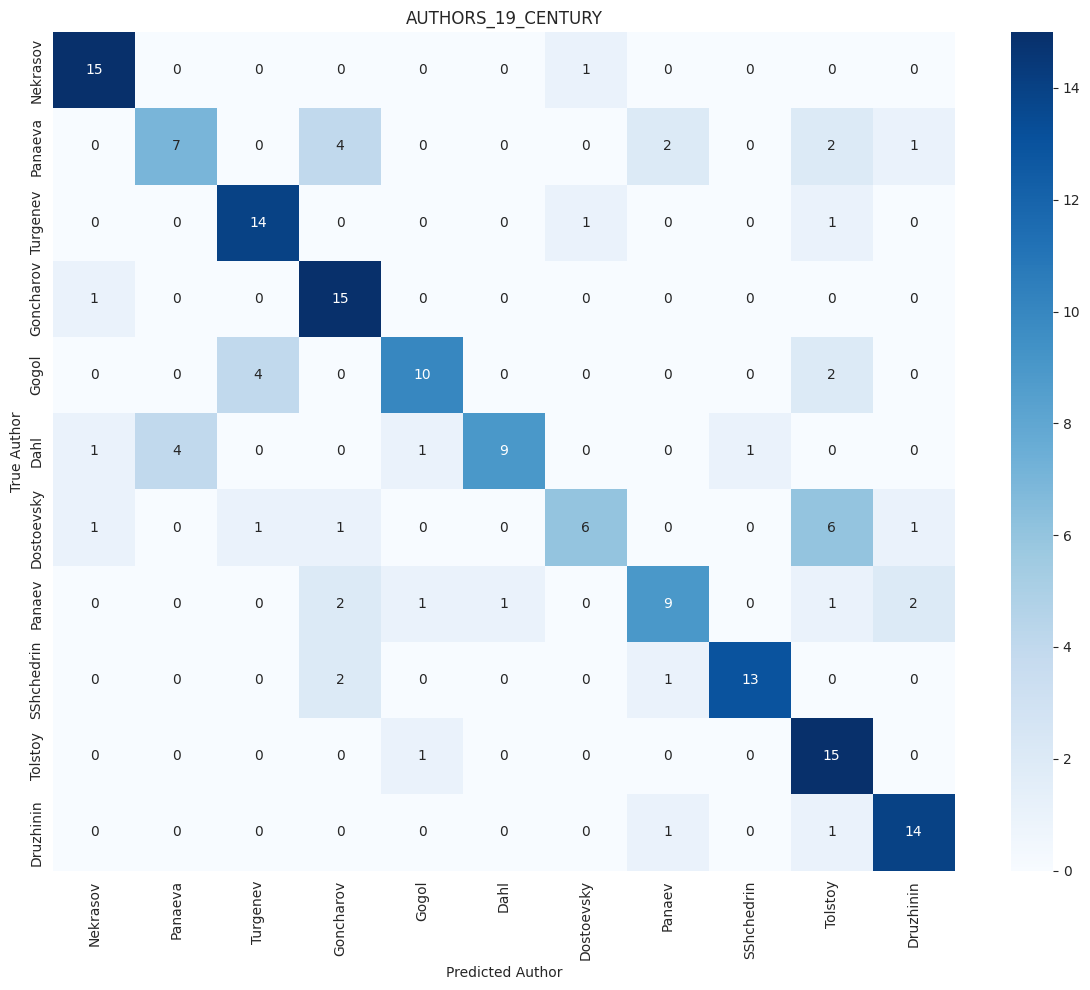

In [17]:
def plot_confusion_matrix(table, title='Confusion Matrix'):
    plt.figure(figsize=(12, 10))
    sns.heatmap(table, annot=True, fmt='d', cmap='Blues')
    plt.title(title)
    plt.xlabel('Predicted Author')
    plt.ylabel('True Author')
    plt.tight_layout()
    plt.show()

plot_confusion_matrix(result_19c['table'], 'AUTHORS_19_CENTURY')

## Делим сырые файлы на части

In [18]:
import re

def split_files_by_parts(file_path: str | Path, split_patterns: list[str], 
                         output_dir: str | Path = None,
                         part_names: list[str] = None) -> dict[str, Path]:
    """
    Разделяет текстовый файл на части по заданным паттернам (regex).
    
    :param file_path: путь к исходному файлу
    :param split_patterns: список regex-паттернов для разделения (ищутся в начале строки)
    :param output_dir: папка для сохранения частей
    :param part_names: имена для частей (по умолчанию используются найденные маркеры)
    :return: словарь {имя_части: путь_к_файлу}
    """
    file_path = Path(file_path)
    text = file_path.read_text(encoding='utf-8')
    
    if output_dir is None:
        output_dir = Path(f'data/raw/Nekrasov_experiment/parts_of_{file_path.stem}/')
    else:
        output_dir = Path(output_dir)
    
    output_dir.mkdir(parents=True, exist_ok=True)
    
    # Находим позиции всех маркеров в тексте
    marker_positions = []
    for pattern in split_patterns:
        for match in re.finditer(pattern, text, re.MULTILINE | re.IGNORECASE):
            marker_positions.append((match.start(), match.group().strip()))
    
    # Сортируем по позиции
    marker_positions.sort(key=lambda x: x[0])
    
    if not marker_positions:
        raise ValueError(f"Ни один маркер не найден в файле: {split_patterns}")
    
    print(f"Найдено {len(marker_positions)} частей в {file_path.name}")
    
    # Разбиваем текст на части
    parts = {}
    for i, (pos, marker) in enumerate(marker_positions):
        # Определяем конец текущей части
        if i + 1 < len(marker_positions):
            end_pos = marker_positions[i + 1][0]
        else:
            end_pos = len(text)
        
        part_text = text[pos:end_pos].strip()
        
        # Имя части
        if part_names and i < len(part_names):
            part_name = part_names[i]
        else:
            part_name = marker
        
        # Безопасное имя файла
        safe_name = re.sub(r'[^\w\s-]', '', part_name)
        safe_name = re.sub(r'\s+', '_', safe_name).strip('_')
        
        output_path = output_dir / f'{i+1:02d}_{safe_name}.txt'
        output_path.write_text(part_text, encoding='utf-8')
        
        parts[part_name] = output_path
        print(f"  {i+1:2d}. {part_name}: {len(part_text):,} символов -> {output_path.name}")
    
    return parts


# Паттерны для "Три страны света" (10 частей)
TRI_STRANY_PATTERNS = [
    r'^ПРОЛОГ',
    r'^ЧАСТЬ ПЕРВАЯ',
    r'^ЧАСТЬ ВТОРАЯ',
    r'^ЧАСТЬ ТРЕТЬЯ',
    r'^ЧАСТЬ ЧЕТВЕРТАЯ',
    r'^ЧАСТЬ ПЯТАЯ',
    r'^ЧАСТЬ ШЕСТАЯ',
    r'^ЧАСТЬ СЕДЬМАЯ',
    r'^ЧАСТЬ ВОСЬМАЯ',
    r'^ЗАКЛЮЧЕНИЕ'
]

TRI_STRANY_NAMES = [
    'Пролог', 'Часть 1', 'Часть 2', 'Часть 3', 'Часть 4',
    'Часть 5', 'Часть 6', 'Часть 7', 'Часть 8', 'Заключение'
]

# Паттерны для "Мёртвое озеро" (16 частей: 1-15 + Эпилог)
# Учитываем опечатки "Ч асть" (с пробелом)
MERTVOYE_OZERO_PATTERNS = [
    r'^Ч\s*асть первая',
    r'^Ч\s*асть вторая',
    r'^Ч\s*асть третья',
    r'^Ч\s*асть четвертая',
    r'^Ч\s*асть пятая',
    r'^Ч\s*асть шестая',
    r'^Ч\s*асть седьмая',
    r'^Ч\s*асть восьмая',
    r'^Ч\s*асть девятая',
    r'^Ч\s*асть десятая',
    r'^Ч\s*асть одиннадцатая',
    r'^Ч\s*асть двенадцатая',
    r'^Ч\s*асть тринадцатая',
    r'^Ч\s*асть четырнадцатая',
    r'^Ч\s*асть пятнадцатая',
    r'^Эпилог'
]

MERTVOYE_OZERO_NAMES = [
    'Часть 1', 'Часть 2', 'Часть 3', 'Часть 4', 'Часть 5',
    'Часть 6', 'Часть 7', 'Часть 8', 'Часть 9', 'Часть 10',
    'Часть 11', 'Часть 12', 'Часть 13', 'Часть 14', 'Часть 15',
    'Эпилог'
]

In [19]:
# Разбиваем "Три страны света" на части
tri_strany_parts = split_files_by_parts(
    file_path='data/raw/Nekrasov_experiment/Tri_Strany_Sveta.txt',
    split_patterns=TRI_STRANY_PATTERNS,
    part_names=TRI_STRANY_NAMES
)

print()

# Разбиваем "Мёртвое озеро" на части  
mertvoye_ozero_parts = split_files_by_parts(
    file_path='data/raw/Nekrasov_experiment/Mertvoye_Ozero.txt',
    split_patterns=MERTVOYE_OZERO_PATTERNS,
    part_names=MERTVOYE_OZERO_NAMES
)

Найдено 10 частей в Tri_Strany_Sveta.txt
   1. Пролог: 23,080 символов -> 01_Пролог.txt
   2. Часть 1: 156,753 символов -> 02_Часть_1.txt
   3. Часть 2: 197,694 символов -> 03_Часть_2.txt
   4. Часть 3: 179,833 символов -> 04_Часть_3.txt
   5. Часть 4: 203,296 символов -> 05_Часть_4.txt
   6. Часть 5: 196,916 символов -> 06_Часть_5.txt
   7. Часть 6: 229,207 символов -> 07_Часть_6.txt
   8. Часть 7: 182,876 символов -> 08_Часть_7.txt
   9. Часть 8: 171,421 символов -> 09_Часть_8.txt
  10. Заключение: 12,365 символов -> 10_Заключение.txt

Найдено 16 частей в Mertvoye_Ozero.txt
   1. Часть 1: 87,189 символов -> 01_Часть_1.txt
   2. Часть 2: 103,840 символов -> 02_Часть_2.txt
   3. Часть 3: 79,289 символов -> 03_Часть_3.txt
   4. Часть 4: 112,363 символов -> 04_Часть_4.txt
   5. Часть 5: 68,222 символов -> 05_Часть_5.txt
   6. Часть 6: 106,202 символов -> 06_Часть_6.txt
   7. Часть 7: 100,332 символов -> 07_Часть_7.txt
   8. Часть 8: 78,137 символов -> 08_Часть_8.txt
   9. Часть 9: 83,206



Согласно статье: 16 срезов по 8 КБ на каждую часть.
- 1 — Пролог, 2 — Часть 1, 3 — Часть 2, 4 — Часть 3, 5 — Часть 4
- 6 — Часть 5, 7 — Часть 6, 8 — Часть 7, 9 — Часть 8, 10 — Заключение

In [20]:
# Параметры эксперимента (как в статье)
TABLE7_AUTHORS = ['Nekrasov', 'Panaeva', 'Panaev']
TABLE7_PREPROCESS = 'origcase_withpunct_withstop'
TABLE7_N_SLICES = 16  # 16 срезов по 8 КБ
TABLE7_COMPRESSOR = 'lzma'
TABLE7_LEVEL = 6
TABLE7_TRAIN_KB = 128

# Пути к частям романа "Три страны света"
TRI_STRANY_PARTS_DIR = Path('data/raw/Nekrasov_experiment/parts_of_Tri_Strany_Sveta')
TRI_STRANY_PARTS = [
    ('Пролог', '01_Пролог.txt'),
    ('Часть 1', '02_Часть_1.txt'),
    ('Часть 2', '03_Часть_2.txt'),
    ('Часть 3', '04_Часть_3.txt'),
    ('Часть 4', '05_Часть_4.txt'),
    ('Часть 5', '06_Часть_5.txt'),
    ('Часть 6', '07_Часть_6.txt'),
    ('Часть 7', '08_Часть_7.txt'),
    ('Часть 8', '09_Часть_8.txt'),
    ('Заключение', '10_Заключение.txt'),
]

In [21]:
from src.data_pipeline import clean_text, preprocess_text, STOPWORDS_RU_ENG

def preprocess_part_text(text: str, preprocess_type: str) -> str:
    """
    Применяет предобработку к тексту части романа.
    
    :param text: исходный текст
    :param preprocess_type: тип предобработки (например, 'origcase_withpunct_withstop')
    :return: предобработанный текст
    """
    # Парсим тип предобработки
    parts = preprocess_type.split('_')
    lowercase = parts[0] == 'lower'
    remove_punct = parts[1] == 'nopunct'
    remove_stopwords = parts[2] == 'nostop'
    
    # Базовая очистка
    text = clean_text(text)
    
    # Применяем предобработку
    stopwords_set = STOPWORDS_RU_ENG if remove_stopwords else None
    text = preprocess_text(
        text,
        lowercase=lowercase,
        remove_punct=remove_punct,
        remove_stopwords=remove_stopwords,
        stopwords_set=stopwords_set
    )
    
    return text


def split_text_into_slices(text: str, n_slices: int) -> list[str]:
    """
    Делит текст на n равных частей.
    
    :param text: текст для разделения
    :param n_slices: количество частей
    :return: список строк (слайсов)
    """
    total_len = len(text)
    base_size = total_len // n_slices
    remainder = total_len % n_slices
    
    slices = []
    start = 0
    for i in range(n_slices):
        size = base_size + (1 if i < remainder else 0)
        slices.append(text[start:start + size])
        start += size
    
    return slices


def attribute_part_to_authors(part_text: str, train_authors: list[str], 
                              preprocess_type: str, n_slices: int,
                              compressor: str, lvl: int = 6) -> dict[str, int]:
    """
    Атрибутирует часть романа (разбитую на слайсы) авторам.
    
    :param part_text: текст части романа
    :param train_authors: список авторов для сравнения
    :param preprocess_type: тип предобработки
    :param n_slices: количество слайсов
    :param compressor: компрессор
    :param lvl: уровень сжатия
    :return: словарь {автор: количество_голосов}
    """
    # Загружаем пути к Train.txt авторов и кэшируем phi(T1)
    authors_paths = {}
    phi_T1_cache = {}
    
    for author in train_authors:
        train_path = Path('data/processed') / author / preprocess_type / 'Train.txt'
        if not train_path.exists():
            raise FileNotFoundError(f'Train не найден: {train_path}')
        authors_paths[author] = train_path
        phi_T1_cache[author] = phi(compressor, train_path, None, lvl, phi_T1_cache, author)
    
    # Предобрабатываем текст части
    processed_text = preprocess_part_text(part_text, preprocess_type)
    
    # Разбиваем на слайсы
    slices = split_text_into_slices(processed_text, n_slices)
    
    # Подсчитываем голоса
    attribution_counts = {author: 0 for author in train_authors}
    
    for slice_text in slices:
        # Сохраняем слайс во временный файл
        import tempfile
        with tempfile.NamedTemporaryFile(mode='w', suffix='.txt', delete=False, encoding='utf-8') as f:
            f.write(slice_text)
            temp_path = Path(f.name)
        
        try:
            # Вычисляем phi для всех авторов
            phi_vals = phi_authors(compressor, authors_paths, temp_path, lvl, phi_T1_cache)
            predicted_author = min(phi_vals, key=phi_vals.get)
            attribution_counts[predicted_author] += 1
        finally:
            # Удаляем временный файл
            temp_path.unlink()
    
    return attribution_counts


def run_table7_experiment(parts_dir: Path, parts_list: list[tuple[str, str]], 
                          train_authors: list[str], preprocess_type: str,
                          n_slices: int, compressor: str, lvl: int = 6) -> pd.DataFrame:
    """
    Запускает эксперимент для Таблицы 7: атрибуция частей романа.
    
    :param parts_dir: папка с частями романа
    :param parts_list: список кортежей (название_части, имя_файла)
    :param train_authors: список авторов для сравнения
    :param preprocess_type: тип предобработки
    :param n_slices: количество слайсов на часть
    :param compressor: компрессор
    :param lvl: уровень сжатия
    :return: DataFrame с результатами
    """
    results = []
    
    for part_name, part_filename in parts_list:
        part_path = parts_dir / part_filename
        if not part_path.exists():
            print(f"Файл не найден: {part_path}")
            continue
        
        print(f"Обработка: {part_name}...")
        part_text = part_path.read_text(encoding='utf-8')
        
        counts = attribute_part_to_authors(
            part_text, train_authors, preprocess_type, 
            n_slices, compressor, lvl
        )
        
        row = {'Часть': part_name}
        row.update(counts)
        results.append(row)
    
    df = pd.DataFrame(results)
    df = df.set_index('Часть')
    
    return df

In [22]:
# Генерируем train данные для авторов (если не существуют)
run_data_pipeline(TABLE7_AUTHORS, train_kb=TABLE7_TRAIN_KB, test_kb=64, seed=42)
split_into_slices(TABLE7_AUTHORS, n_slices=TABLE7_N_SLICES)

Генерация датасета
Для Nekrasov!
Готово! Сохранено в папке data/processed/Nekrasov/lower_nopunct_nostop
В train попали: ['певица', 'двадцать пять рублей', 'опытная женщина']
В test: ['ростовщик', 'в сардинии']
Готово! Сохранено в папке data/processed/Nekrasov/lower_nopunct_withstop
В train попали: ['певица', 'двадцать пять рублей', 'опытная женщина']
В test: ['ростовщик', 'в сардинии']
Готово! Сохранено в папке data/processed/Nekrasov/origcase_nopunct_nostop
В train попали: ['певица', 'двадцать пять рублей', 'опытная женщина']
В test: ['ростовщик', 'в сардинии']
Готово! Сохранено в папке data/processed/Nekrasov/origcase_nopunct_withstop
В train попали: ['певица', 'двадцать пять рублей', 'опытная женщина']
В test: ['ростовщик', 'в сардинии']
Готово! Сохранено в папке data/processed/Nekrasov/lower_withpunct_nostop
В train попали: ['певица', 'двадцать пять рублей', 'опытная женщина']
В test: ['ростовщик', 'в сардинии']
Готово! Сохранено в папке data/processed/Nekrasov/origcase_withpunct_n

In [23]:
# Запуск эксперимента для Таблицы 7
table7_results = run_table7_experiment(
    parts_dir=TRI_STRANY_PARTS_DIR,
    parts_list=TRI_STRANY_PARTS,
    train_authors=TABLE7_AUTHORS,
    preprocess_type=TABLE7_PREPROCESS,
    n_slices=TABLE7_N_SLICES,
    compressor=TABLE7_COMPRESSOR,
    lvl=TABLE7_LEVEL
)

Обработка: Пролог...
Обработка: Часть 1...
Обработка: Часть 2...
Обработка: Часть 3...
Обработка: Часть 4...
Обработка: Часть 5...
Обработка: Часть 6...
Обработка: Часть 7...
Обработка: Часть 8...
Обработка: Заключение...


In [24]:
# Отображение результатов Таблицы 7
print("Таблица 7. Атрибуция частей романа «Три страны света» (16 срезов по 8 КБ)")
print("1 — Пролог, 2-9 — Части 1-8, 10 — Заключение")

table7_transposed = table7_results.T
table7_transposed.columns = [f'{i+1}' for i in range(len(table7_transposed.columns))]
table7_transposed

Таблица 7. Атрибуция частей романа «Три страны света» (16 срезов по 8 КБ)
1 — Пролог, 2-9 — Части 1-8, 10 — Заключение


,1,2,3,4,5,6,7,8,9,10
Nekrasov,0,0,1,0,0,1,0,0,1,4
Panaeva,14,13,10,10,13,13,12,14,12,8
Panaev,2,3,5,6,3,2,4,2,3,4


## Таблица 8: Атрибуция частей романа «Мёртвое озеро»

Согласно статье: 16 срезов по 8 КБ на каждую часть.
- 1-15 — Части 1-15, 16 — Эпилог

In [25]:
# Параметры эксперимента для Таблицы 8 (те же, что для Таблицы 7)
TABLE8_AUTHORS = ['Nekrasov', 'Panaeva', 'Panaev']
TABLE8_PREPROCESS = 'origcase_withpunct_withstop'
TABLE8_N_SLICES = 16  # 16 срезов по 8 КБ
TABLE8_COMPRESSOR = 'lzma'
TABLE8_LEVEL = 6

# Пути к частям романа "Мёртвое озеро"
MERTVOYE_OZERO_PARTS_DIR = Path('data/raw/Nekrasov_experiment/parts_of_Mertvoye_Ozero')
MERTVOYE_OZERO_PARTS = [
    ('Часть 1', '01_Часть_1.txt'),
    ('Часть 2', '02_Часть_2.txt'),
    ('Часть 3', '03_Часть_3.txt'),
    ('Часть 4', '04_Часть_4.txt'),
    ('Часть 5', '05_Часть_5.txt'),
    ('Часть 6', '06_Часть_6.txt'),
    ('Часть 7', '07_Часть_7.txt'),
    ('Часть 8', '08_Часть_8.txt'),
    ('Часть 9', '09_Часть_9.txt'),
    ('Часть 10', '10_Часть_10.txt'),
    ('Часть 11', '11_Часть_11.txt'),
    ('Часть 12', '12_Часть_12.txt'),
    ('Часть 13', '13_Часть_13.txt'),
    ('Часть 14', '14_Часть_14.txt'),
    ('Часть 15', '15_Часть_15.txt'),
    ('Эпилог', '16_Эпилог.txt'),
]

In [26]:
# Запуск эксперимента для Таблицы 8
table8_results = run_table7_experiment(
    parts_dir=MERTVOYE_OZERO_PARTS_DIR,
    parts_list=MERTVOYE_OZERO_PARTS,
    train_authors=TABLE8_AUTHORS,
    preprocess_type=TABLE8_PREPROCESS,
    n_slices=TABLE8_N_SLICES,
    compressor=TABLE8_COMPRESSOR,
    lvl=TABLE8_LEVEL
)

Обработка: Часть 1...
Обработка: Часть 2...
Обработка: Часть 3...
Обработка: Часть 4...
Обработка: Часть 5...
Обработка: Часть 6...
Обработка: Часть 7...
Обработка: Часть 8...
Обработка: Часть 9...
Обработка: Часть 10...
Обработка: Часть 11...
Обработка: Часть 12...
Обработка: Часть 13...
Обработка: Часть 14...
Обработка: Часть 15...
Обработка: Эпилог...


In [27]:
# Отображение результатов Таблицы 8
print("Таблица 8. Атрибуция частей романа «Мёртвое озеро» (16 срезов по 8 КБ)")
print("1-15 — Части 1-15, 16 — Эпилог")

table8_transposed = table8_results.T
table8_transposed.columns = [f'{i+1}' for i in range(len(table8_transposed.columns))]
table8_transposed

Таблица 8. Атрибуция частей романа «Мёртвое озеро» (16 срезов по 8 КБ)
1-15 — Части 1-15, 16 — Эпилог


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
Nekrasov,0,1,4,4,8,3,4,1,5,9,6,11,3,5,6,10
Panaeva,12,15,6,12,7,9,9,12,9,5,1,3,10,7,9,4
Panaev,4,0,6,0,1,4,3,3,2,2,9,2,3,4,1,2


In [28]:
# Интерпретация результатов
print("=" * 70)
print("ИНТЕРПРЕТАЦИЯ РЕЗУЛЬТАТОВ ТАБЛИЦЫ 8")
print("=" * 70)

for idx, (part_name, row) in enumerate(table8_results.iterrows()):
    winner = row.idxmax()
    winner_votes = row.max()
    total_votes = row.sum()
    pct = winner_votes / total_votes * 100
    print(f"{idx+1:2d}. {part_name:15s} -> {winner:10s} ({winner_votes:2d}/{total_votes:2d} = {pct:5.1f}%)")

print()
print("Согласно статье:")
print("- Авторство И. Панаева полностью исключается")
print("- Части 6, 11 и 12 атрибутируются Н. Некрасову")
print("- Весь основной текст написан А. Панаевой — она истинный автор романа")

ИНТЕРПРЕТАЦИЯ РЕЗУЛЬТАТОВ ТАБЛИЦЫ 8
 1. Часть 1         -> Panaeva    (12/16 =  75.0%)
 2. Часть 2         -> Panaeva    (15/16 =  93.8%)
 3. Часть 3         -> Panaeva    ( 6/16 =  37.5%)
 4. Часть 4         -> Panaeva    (12/16 =  75.0%)
 5. Часть 5         -> Nekrasov   ( 8/16 =  50.0%)
 6. Часть 6         -> Panaeva    ( 9/16 =  56.2%)
 7. Часть 7         -> Panaeva    ( 9/16 =  56.2%)
 8. Часть 8         -> Panaeva    (12/16 =  75.0%)
 9. Часть 9         -> Panaeva    ( 9/16 =  56.2%)
10. Часть 10        -> Nekrasov   ( 9/16 =  56.2%)
11. Часть 11        -> Panaev     ( 9/16 =  56.2%)
12. Часть 12        -> Nekrasov   (11/16 =  68.8%)
13. Часть 13        -> Panaeva    (10/16 =  62.5%)
14. Часть 14        -> Panaeva    ( 7/16 =  43.8%)
15. Часть 15        -> Panaeva    ( 9/16 =  56.2%)
16. Эпилог          -> Nekrasov   (10/16 =  62.5%)

Согласно статье:
- Авторство И. Панаева полностью исключается
- Части 6, 11 и 12 атрибутируются Н. Некрасову
- Весь основной текст написан А. Панае

---
## 6. Задача выбора лучшего перевода (Цель c)

In [189]:
TRAIN_KB = 128
TEST_KB = 128
N_SLICES = 32

AUTHORS_SINGLE = ['Chukovsky', 'Engelhardt', 'Darouzes']

In [190]:
run_data_pipeline(AUTHORS_SINGLE, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=42)
split_into_slices(AUTHORS_SINGLE, N_SLICES)

Генерация датасета
Для Chukovsky!
Готово! Сохранено в папке data/processed/Chukovsky/lower_nopunct_nostop
В train попали: ['Доктор Айболит-2']
В test: ['Доктор Айболит-1']
Готово! Сохранено в папке data/processed/Chukovsky/lower_nopunct_withstop
В train попали: ['Доктор Айболит-2']
В test: ['Доктор Айболит-1']
Готово! Сохранено в папке data/processed/Chukovsky/origcase_nopunct_nostop
В train попали: ['Доктор Айболит-2']
В test: ['Доктор Айболит-1']
Готово! Сохранено в папке data/processed/Chukovsky/origcase_nopunct_withstop
В train попали: ['Доктор Айболит-2']
В test: ['Доктор Айболит-1']
Готово! Сохранено в папке data/processed/Chukovsky/lower_withpunct_nostop
В train попали: ['Доктор Айболит-2']
В test: ['Доктор Айболит-1']
Готово! Сохранено в папке data/processed/Chukovsky/origcase_withpunct_nostop
В train попали: ['Доктор Айболит-2']
В test: ['Доктор Айболит-1']
Готово! Сохранено в папке data/processed/Chukovsky/lower_withpunct_withstop
В train попали: ['Доктор Айболит-2']
В test: 

In [ ]:
def run_experiment(authors, preprocess_type, n_slices, compressor, lvl=6):
    table = build_table(authors, preprocess_type, n_slices, compressor, lvl)
    chi2, p_value, df = significance_level(table)
    accuracy = get_accuracy(table)
    return {
        'table': table,
        'chi2': chi2,
        'p_value': p_value,
        'df': df,
        'accuracy': accuracy
    }

def plot_confusion_matrix(table, title='Confusion Matrix'):
    plt.figure(figsize=(12, 10))
    ax = sns.heatmap(
        table,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=True
    )
    ax.set_title(title, pad=20)
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position('top')
    ax.tick_params(axis='x', length=0)
    ax.set_xlabel('Предсказанный автор')
    ax.set_ylabel('Истинный автор')
    plt.xticks(rotation=0, ha='center')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


In [192]:
result = run_experiment(
    authors=AUTHORS_SINGLE,
    preprocess_type='origcase_withpunct_withstop',
    n_slices=N_SLICES,
    compressor='lzma',
    lvl=6
)
print(f"chi2 = {result['chi2']:.1f}, p-value = {result['p_value']:.2e}, Accuracy = {result['accuracy']:.2%}")
result['table']

chi2 = 192.0, p-value = 0.00e+00, Accuracy = 100.00%


,Chukovsky,Engelhardt,Darouzes
Chukovsky,32,0,0
Engelhardt,0,32,0
Darouzes,0,0,32


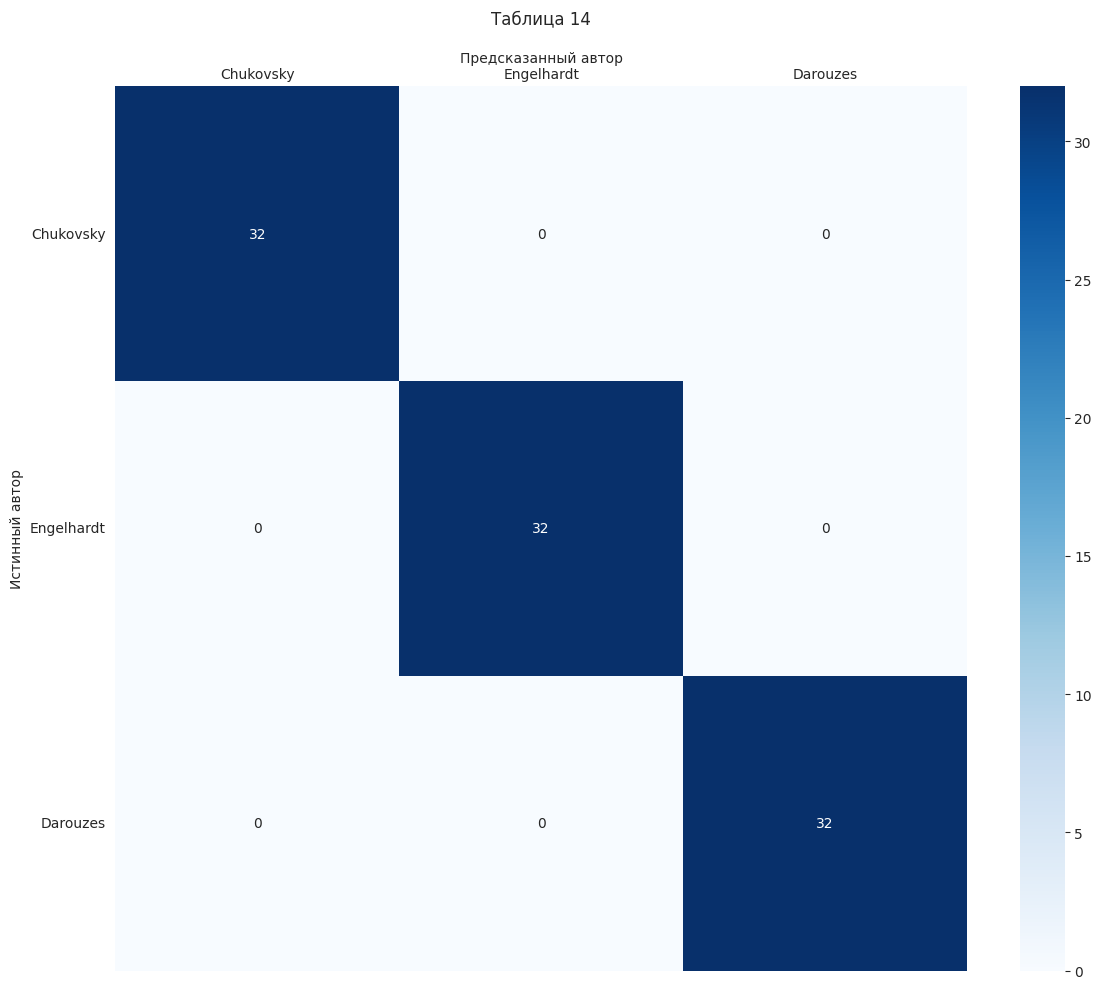

In [193]:
plot_confusion_matrix(result['table'], 'Таблица 14')

In [194]:
TRAIN_KB = 128
TEST_KB = 128
N_SLICES = 32

authors_train_c = ['Chukovsky_translator', 'Engelhardt_translator', 'Darouzes_translator']

In [195]:
run_data_pipeline(authors=authors_train_c, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=42)

Генерация датасета
Для Chukovsky_translator!
Готово! Сохранено в папке data/processed/Chukovsky_translator/lower_nopunct_nostop
В train попали: ['Рики-тики-тави (перевод)']
В test: ['Волшебная лавка (перевод)']
Готово! Сохранено в папке data/processed/Chukovsky_translator/lower_nopunct_withstop
В train попали: ['Рики-тики-тави (перевод)']
В test: ['Волшебная лавка (перевод)']
Готово! Сохранено в папке data/processed/Chukovsky_translator/origcase_nopunct_nostop
В train попали: ['Рики-тики-тави (перевод)']
В test: ['Волшебная лавка (перевод)']
Готово! Сохранено в папке data/processed/Chukovsky_translator/origcase_nopunct_withstop
В train попали: ['Рики-тики-тави (перевод)']
В test: ['Волшебная лавка (перевод)']
Готово! Сохранено в папке data/processed/Chukovsky_translator/lower_withpunct_nostop
В train попали: ['Рики-тики-тави (перевод)']
В test: ['Волшебная лавка (перевод)']
Готово! Сохранено в папке data/processed/Chukovsky_translator/origcase_withpunct_nostop
В train попали: ['Рики-ти

In [196]:
authors_test_c = ['Chukovsky_Tom', 'Engelhardt_Tom', 'Darouzes_Tom']
run_data_pipeline(authors=authors_test_c, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=2025)
split_into_slices(authors=authors_test_c, n_slices=N_SLICES)

Генерация датасета
Для Chukovsky_Tom!
Готово! Сохранено в папке data/processed/Chukovsky_Tom/lower_nopunct_nostop
В train попали: []
В test: ['tom']
Готово! Сохранено в папке data/processed/Chukovsky_Tom/lower_nopunct_withstop
В train попали: []
В test: ['tom']
Готово! Сохранено в папке data/processed/Chukovsky_Tom/origcase_nopunct_nostop
В train попали: []
В test: ['tom']
Готово! Сохранено в папке data/processed/Chukovsky_Tom/origcase_nopunct_withstop
В train попали: []
В test: ['tom']
Готово! Сохранено в папке data/processed/Chukovsky_Tom/lower_withpunct_nostop
В train попали: []
В test: ['tom']
Готово! Сохранено в папке data/processed/Chukovsky_Tom/origcase_withpunct_nostop
В train попали: []
В test: ['tom']
Готово! Сохранено в папке data/processed/Chukovsky_Tom/lower_withpunct_withstop
В train попали: []
В test: ['tom']
Готово! Сохранено в папке data/processed/Chukovsky_Tom/origcase_withpunct_withstop
В train попали: []
В test: ['tom']
Для Darouzes_Tom!
Готово! Сохранено в папке da

In [197]:
def run_multi_book_attribution(train_authors: list[str], test_books: dict[str, str], 
                                preprocess_type: str, n_slices: int, 
                                compressor: str, lvl: int = 6) -> dict:
    """
    Атрибуция нескольких книг одновременно.
    
    :param train_authors: список авторов для обучения (их Train.txt используются)
    :param test_books: словарь {название_книги: имя_папки_автора}
                       например: {'Двенадцать стульев': 'Ilf_12_chairs', 'Золотой телёнок': 'Ilf_golden_calf'}
    :param preprocess_type: тип предобработки
    :param n_slices: количество слайсов на книгу
    :param compressor: компрессор
    :param lvl: уровень сжатия
    :return: dict с table, chi2, p_value
    """
    authors_paths = {}
    phi_T1_cache = {}
    
    # Загружаем train-тексты
    for author in train_authors:
        train_path = Path('data/processed') / author / preprocess_type / 'Train.txt'
        if not train_path.exists():
            raise FileNotFoundError(f'Train не найден: {train_path}')
        authors_paths[author] = train_path
        phi_T1_cache[author] = phi(compressor, train_path, None, lvl, phi_T1_cache, author)
    
    # Таблица результатов: строки — книги, столбцы — авторы
    results = []
    
    for book_name, book_folder in test_books.items():
        attribution_counts = {author: 0 for author in train_authors}
        slices_dir = Path('data/processed') / book_folder / preprocess_type / f'{n_slices}_slices'
        
        for i in range(n_slices):
            slice_path = slices_dir / f'{i}_slice.txt'
            if not slice_path.exists():
                raise FileNotFoundError(f'Слайс {i} не найден: {slice_path}')
            
            phi_vals = phi_authors(compressor, authors_paths, slice_path, lvl, phi_T1_cache)
            predicted_author = min(phi_vals, key=phi_vals.get)
            attribution_counts[predicted_author] += 1
        
        row = {'Произведение': book_name}
        row.update(attribution_counts)
        results.append(row)
    
    table = pd.DataFrame(results).set_index('Произведение')
    
    # Хи-квадрат для таблицы NxM
    chi2, p_value, df = significance_level(table)
    
    return {
        'table': table,
        'chi2': chi2,
        'p_value': p_value,
        'df': df
    }


In [198]:
result_table7 = run_multi_book_attribution(
    train_authors=authors_train_c,
    test_books={
        'Chukovsky_Tom': 'Chukovsky_Tom',
        'Engelhardt_Tom': 'Engelhardt_Tom',
        'Darouzes_Tom': 'Darouzes_Tom'
    },
    preprocess_type='origcase_withpunct_withstop',
    n_slices=N_SLICES,
    compressor='lzma',
    lvl=1
)

In [199]:
result_table7['table']

,Chukovsky_translator,Engelhardt_translator,Darouzes_translator
Произведение,,,
Chukovsky_Tom,6,11,15
Engelhardt_Tom,1,24,7
Darouzes_Tom,0,13,19


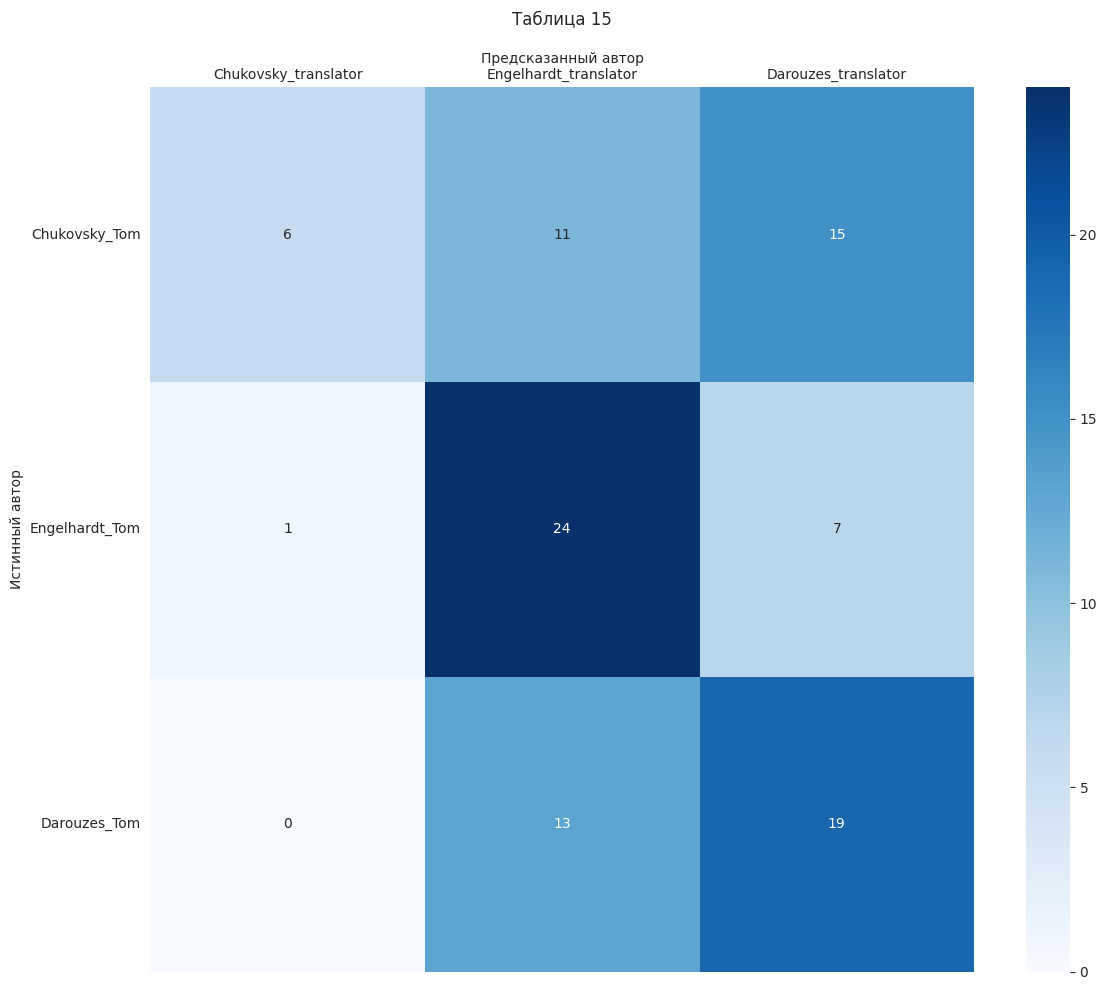

In [200]:
plot_confusion_matrix(result_table7['table'], 'Таблица 15' )

In [201]:
TRAIN_KB = 128
TEST_KB = 128
N_SLICES = 32

authors_train_c = ['Chukovsky', 'Engelhardt', 'Darouzes']

In [202]:
run_data_pipeline(authors=authors_train_c, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=1231)

Генерация датасета
Для Chukovsky!
Готово! Сохранено в папке data/processed/Chukovsky/lower_nopunct_nostop
В train попали: ['Доктор Айболит-1']
В test: ['Доктор Айболит-2']
Готово! Сохранено в папке data/processed/Chukovsky/lower_nopunct_withstop
В train попали: ['Доктор Айболит-1']
В test: ['Доктор Айболит-2']
Готово! Сохранено в папке data/processed/Chukovsky/origcase_nopunct_nostop
В train попали: ['Доктор Айболит-1']
В test: ['Доктор Айболит-2']
Готово! Сохранено в папке data/processed/Chukovsky/origcase_nopunct_withstop
В train попали: ['Доктор Айболит-1']
В test: ['Доктор Айболит-2']
Готово! Сохранено в папке data/processed/Chukovsky/lower_withpunct_nostop
В train попали: ['Доктор Айболит-1']
В test: ['Доктор Айболит-2']
Готово! Сохранено в папке data/processed/Chukovsky/origcase_withpunct_nostop
В train попали: ['Доктор Айболит-1']
В test: ['Доктор Айболит-2']
Готово! Сохранено в папке data/processed/Chukovsky/lower_withpunct_withstop
В train попали: ['Доктор Айболит-1']
В test: 

In [203]:
authors_test_c = ['Chukovsky_Tom', 'Engelhardt_Tom', 'Darouzes_Tom']
run_data_pipeline(authors=authors_test_c, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=2025)
split_into_slices(authors=authors_test_c, n_slices=N_SLICES)

Генерация датасета
Для Chukovsky_Tom!
Готово! Сохранено в папке data/processed/Chukovsky_Tom/lower_nopunct_nostop
В train попали: []
В test: ['tom']
Готово! Сохранено в папке data/processed/Chukovsky_Tom/lower_nopunct_withstop
В train попали: []
В test: ['tom']
Готово! Сохранено в папке data/processed/Chukovsky_Tom/origcase_nopunct_nostop
В train попали: []
В test: ['tom']
Готово! Сохранено в папке data/processed/Chukovsky_Tom/origcase_nopunct_withstop
В train попали: []
В test: ['tom']
Готово! Сохранено в папке data/processed/Chukovsky_Tom/lower_withpunct_nostop
В train попали: []
В test: ['tom']
Готово! Сохранено в папке data/processed/Chukovsky_Tom/origcase_withpunct_nostop
В train попали: []
В test: ['tom']
Готово! Сохранено в папке data/processed/Chukovsky_Tom/lower_withpunct_withstop
В train попали: []
В test: ['tom']
Готово! Сохранено в папке data/processed/Chukovsky_Tom/origcase_withpunct_withstop
В train попали: []
В test: ['tom']
Для Darouzes_Tom!
Готово! Сохранено в папке da

In [204]:
result_table7 = run_multi_book_attribution(
    train_authors=authors_train_c,
    test_books={
        'Chukovsky_Tom': 'Chukovsky_Tom',
        'Engelhardt_Tom': 'Engelhardt_Tom',
        'Darouzes_Tom': 'Darouzes_Tom'
    },
    preprocess_type='origcase_withpunct_withstop',
    n_slices=N_SLICES,
    compressor='lzma',
    lvl=1
)

In [205]:
result_table7['table']

,Chukovsky,Engelhardt,Darouzes
Произведение,,,
Chukovsky_Tom,10,2,20
Engelhardt_Tom,4,5,23
Darouzes_Tom,4,3,25


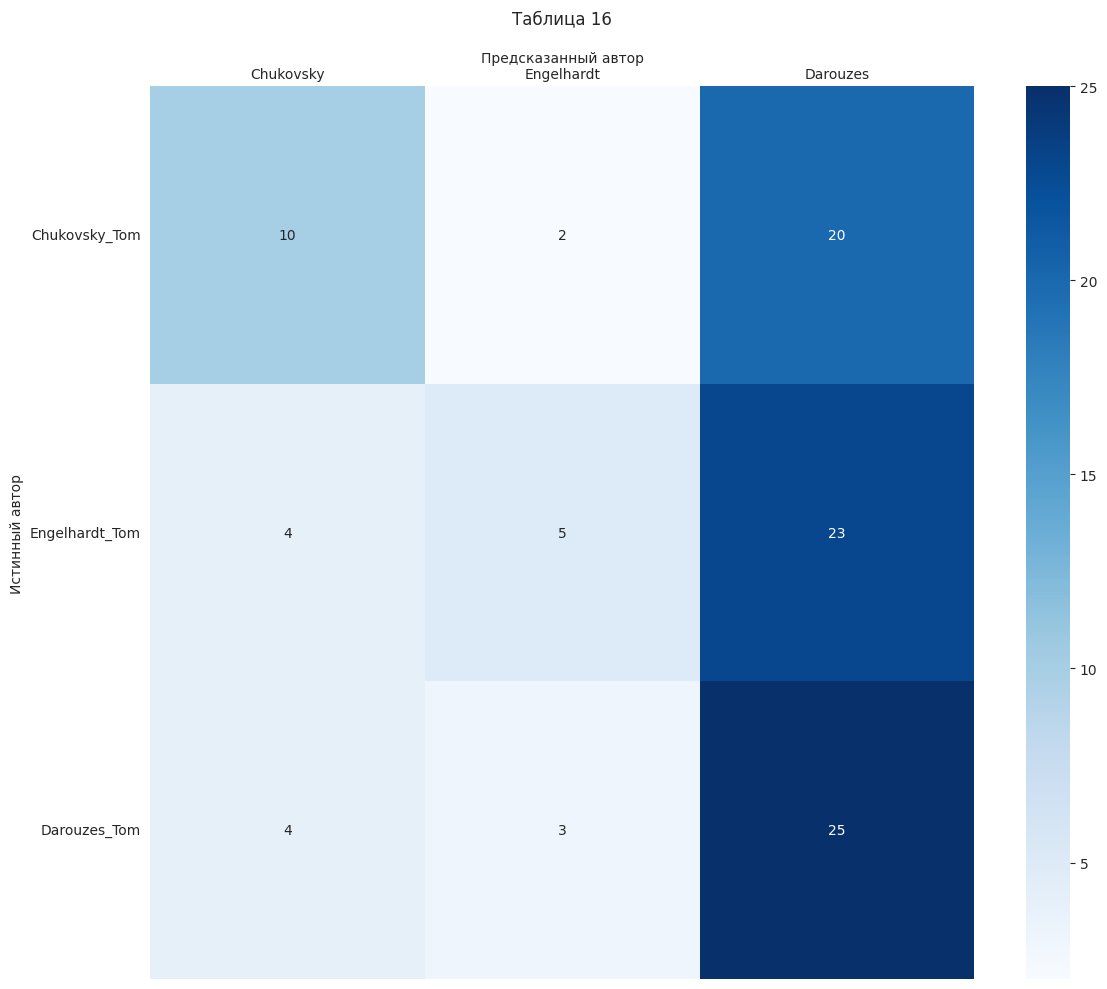

In [206]:
plot_confusion_matrix(result_table7['table'], "Таблица 16")

In [207]:
TRAIN_KB = 128
TEST_KB = 128
N_SLICES = 32


AUTHORS_ONE_1 = ['Kipling_Chukovsky', 'Twain_Chukovsky', 'Wells_Chukovsky']
AUTHORS_ONE_2 = ['Engelhardt_Doyle', 'Engelhardt_Marryat', 'Twain_Engelhardt']
AUTHORS_ONE_3 = ['Dickens_Darouzes','Kipling_Darouzes','Twain_Darouzes']

In [208]:
def run_experiment(authors, preprocess_type, n_slices, compressor, lvl=6):
    table = build_table(authors, preprocess_type, n_slices, compressor, lvl)
    chi2, p_value, df = significance_level(table)
    accuracy = get_accuracy(table)
    return {
        'table': table,
        'chi2': chi2,
        'p_value': p_value,
        'df': df,
        'accuracy': accuracy
    }


In [209]:
run_data_pipeline(AUTHORS_ONE_1, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=42)
split_into_slices(AUTHORS_ONE_1, N_SLICES)

result = run_experiment(
    authors=AUTHORS_ONE_1,
    preprocess_type='origcase_withpunct_withstop',
    n_slices=N_SLICES,
    compressor='lzma',
    lvl=6
)
print(f"chi2 = {result['chi2']:.1f}, p-value = {result['p_value']:.2e}, Accuracy = {result['accuracy']:.2%}")
result['table']

Генерация датасета
Для Kipling_Chukovsky!
Готово! Сохранено в папке data/processed/Kipling_Chukovsky/lower_nopunct_nostop
В train попали: ['Рики-тики-тави (перевод)-2']
В test: ['Рики-тики-тави (перевод)']
Готово! Сохранено в папке data/processed/Kipling_Chukovsky/lower_nopunct_withstop
В train попали: ['Рики-тики-тави (перевод)-2']
В test: ['Рики-тики-тави (перевод)']
Готово! Сохранено в папке data/processed/Kipling_Chukovsky/origcase_nopunct_nostop
В train попали: ['Рики-тики-тави (перевод)-2']
В test: ['Рики-тики-тави (перевод)']
Готово! Сохранено в папке data/processed/Kipling_Chukovsky/origcase_nopunct_withstop
В train попали: ['Рики-тики-тави (перевод)-2']
В test: ['Рики-тики-тави (перевод)']
Готово! Сохранено в папке data/processed/Kipling_Chukovsky/lower_withpunct_nostop
В train попали: ['Рики-тики-тави (перевод)-2']
В test: ['Рики-тики-тави (перевод)']
Готово! Сохранено в папке data/processed/Kipling_Chukovsky/origcase_withpunct_nostop
В train попали: ['Рики-тики-тави (перевод

,Kipling_Chukovsky,Twain_Chukovsky,Wells_Chukovsky
Kipling_Chukovsky,32,0,0
Twain_Chukovsky,0,32,0
Wells_Chukovsky,0,0,32


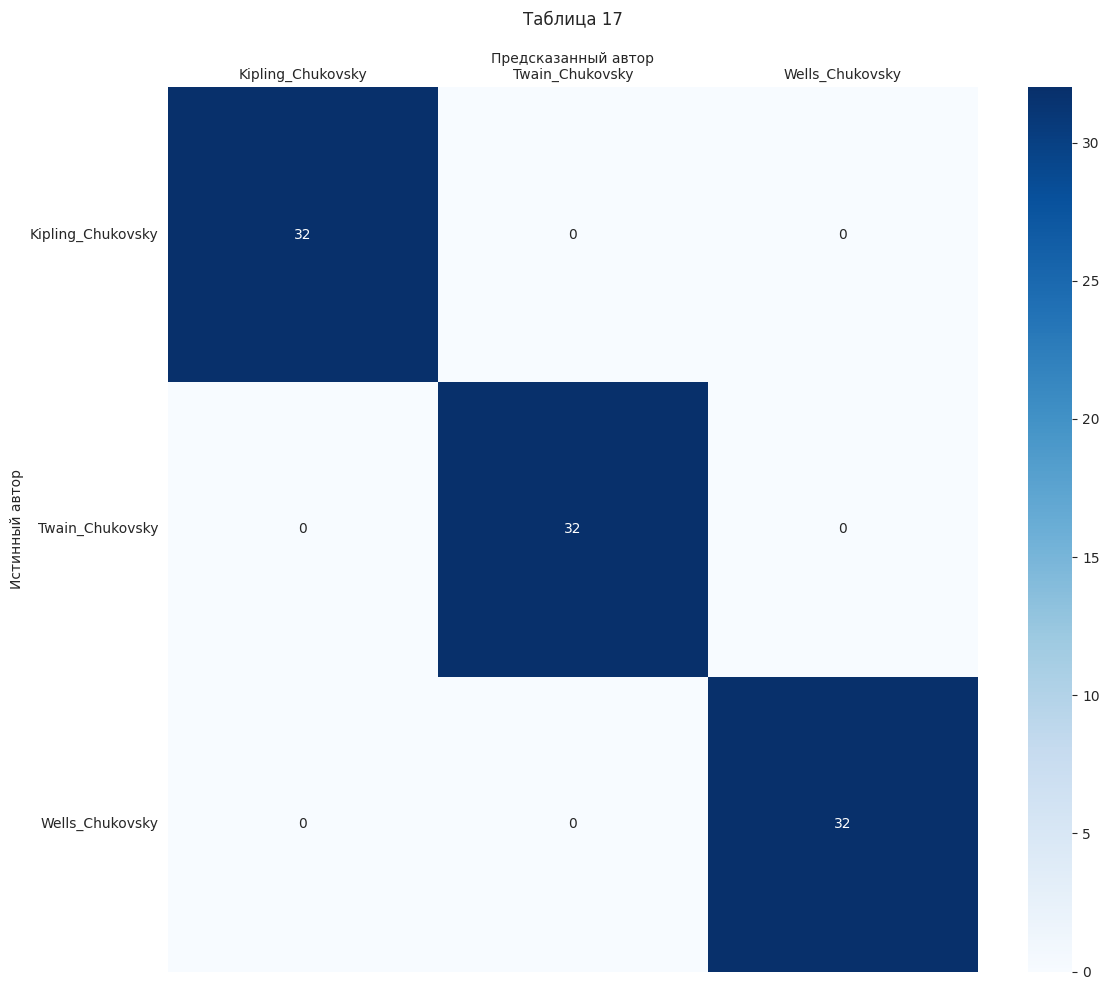

In [210]:
plot_confusion_matrix(result['table'], "Таблица 17")

In [211]:
run_data_pipeline(AUTHORS_ONE_2, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=42)
split_into_slices(AUTHORS_ONE_2, N_SLICES)

result = run_experiment(
    authors=AUTHORS_ONE_2,
    preprocess_type='origcase_withpunct_withstop',
    n_slices=N_SLICES,
    compressor='gzip',
    lvl=1
)
print(f"chi2 = {result['chi2']:.1f}, p-value = {result['p_value']:.2e}, Accuracy = {result['accuracy']:.2%}")
result['table']

Генерация датасета
Для Engelhardt_Doyle!
Готово! Сохранено в папке data/processed/Engelhardt_Doyle/lower_nopunct_nostop
В train попали: ['письма старка монро(перевод дойля) copy']
В test: ['письма старка монро(перевод дойля)']
Готово! Сохранено в папке data/processed/Engelhardt_Doyle/lower_nopunct_withstop
В train попали: ['письма старка монро(перевод дойля) copy']
В test: ['письма старка монро(перевод дойля)']
Готово! Сохранено в папке data/processed/Engelhardt_Doyle/origcase_nopunct_nostop
В train попали: ['письма старка монро(перевод дойля) copy']
В test: ['письма старка монро(перевод дойля)']
Готово! Сохранено в папке data/processed/Engelhardt_Doyle/origcase_nopunct_withstop
В train попали: ['письма старка монро(перевод дойля) copy']
В test: ['письма старка монро(перевод дойля)']
Готово! Сохранено в папке data/processed/Engelhardt_Doyle/lower_withpunct_nostop
В train попали: ['письма старка монро(перевод дойля) copy']
В test: ['письма старка монро(перевод дойля)']
Готово! Сохранено

,Engelhardt_Doyle,Engelhardt_Marryat,Twain_Engelhardt
Engelhardt_Doyle,16,4,12
Engelhardt_Marryat,0,23,9
Twain_Engelhardt,0,1,31


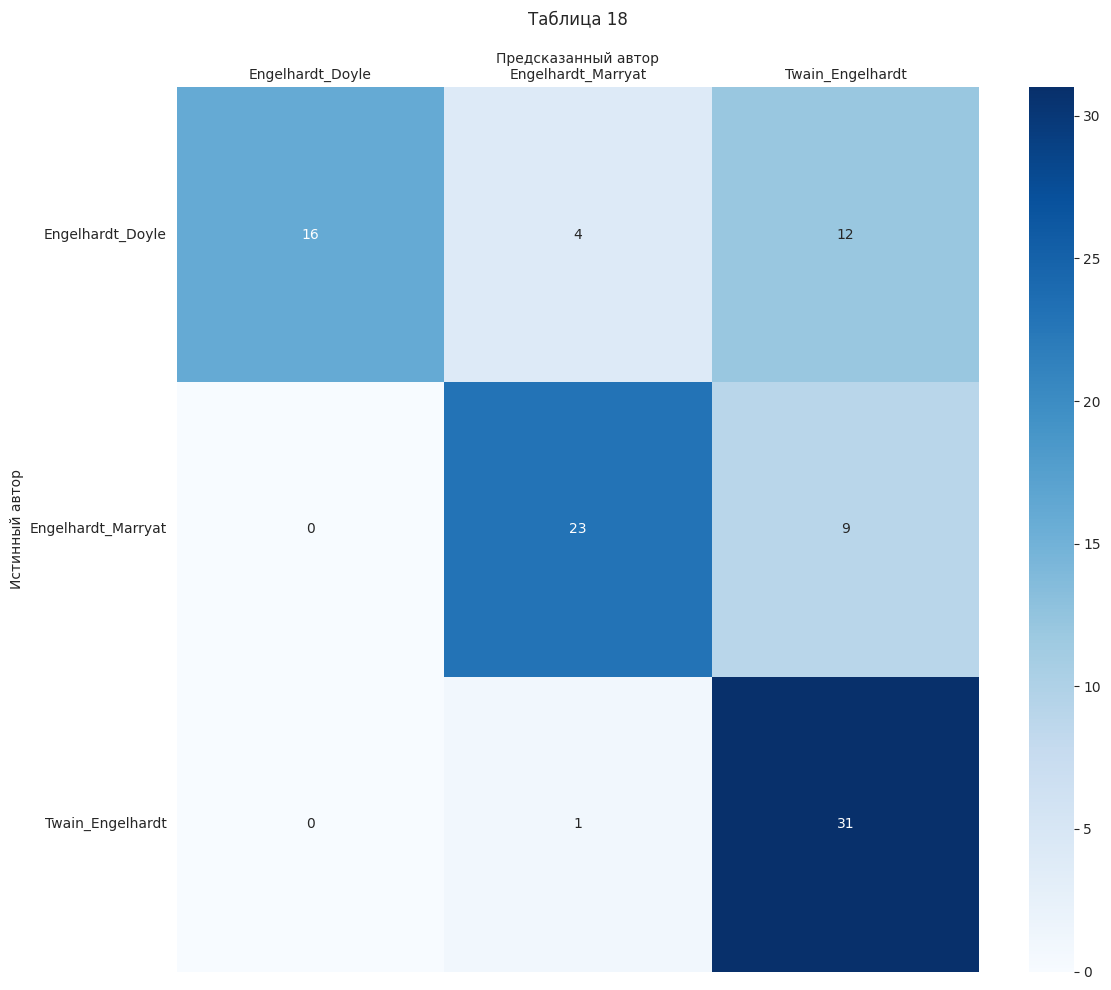

In [212]:
plot_confusion_matrix(result['table'], "Таблица 18")

In [213]:
run_data_pipeline(AUTHORS_ONE_3, train_kb=TRAIN_KB, test_kb=TEST_KB, seed=42)
split_into_slices(AUTHORS_ONE_3, N_SLICES)

result = run_experiment(
    authors=AUTHORS_ONE_3,
    preprocess_type='origcase_withpunct_withstop',
    n_slices=N_SLICES,
    compressor='gzip',
    lvl=1
)
print(f"chi2 = {result['chi2']:.1f}, p-value = {result['p_value']:.2e}, Accuracy = {result['accuracy']:.2%}")
result['table']

Генерация датасета
Для Dickens_Darouzes!
Готово! Сохранено в папке data/processed/Dickens_Darouzes/lower_nopunct_nostop
В train попали: ['Диккенс Чарльз. Наш общий друг (Книга 3 и 4) copy']
В test: ['Диккенс Чарльз. Наш общий друг (Книга 3 и 4)']
Готово! Сохранено в папке data/processed/Dickens_Darouzes/lower_nopunct_withstop
В train попали: ['Диккенс Чарльз. Наш общий друг (Книга 3 и 4) copy']
В test: ['Диккенс Чарльз. Наш общий друг (Книга 3 и 4)']
Готово! Сохранено в папке data/processed/Dickens_Darouzes/origcase_nopunct_nostop
В train попали: ['Диккенс Чарльз. Наш общий друг (Книга 3 и 4) copy']
В test: ['Диккенс Чарльз. Наш общий друг (Книга 3 и 4)']
Готово! Сохранено в папке data/processed/Dickens_Darouzes/origcase_nopunct_withstop
В train попали: ['Диккенс Чарльз. Наш общий друг (Книга 3 и 4) copy']
В test: ['Диккенс Чарльз. Наш общий друг (Книга 3 и 4)']
Готово! Сохранено в папке data/processed/Dickens_Darouzes/lower_withpunct_nostop
В train попали: ['Диккенс Чарльз. Наш общий 

,Dickens_Darouzes,Kipling_Darouzes,Twain_Darouzes
Dickens_Darouzes,29,3,0
Kipling_Darouzes,0,32,0
Twain_Darouzes,2,3,27


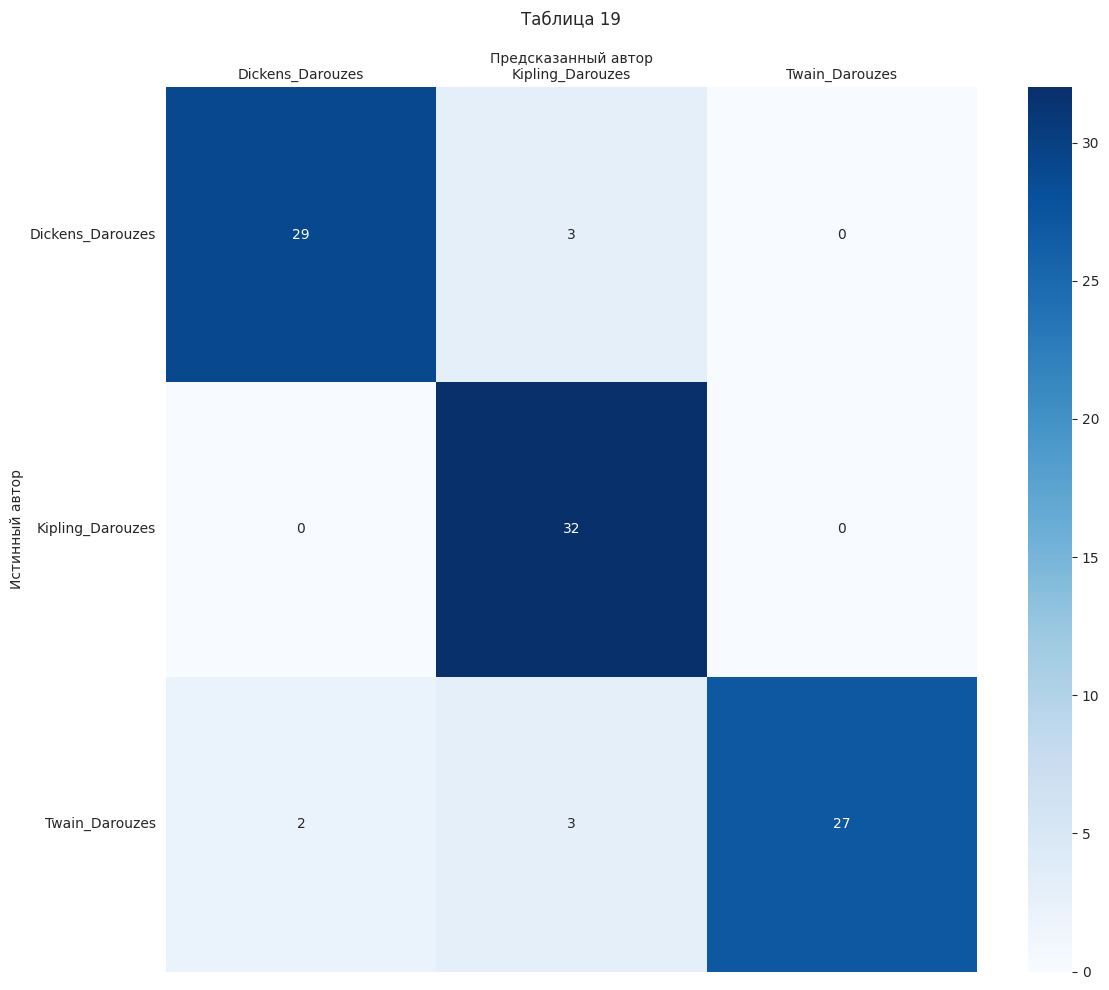

In [214]:
plot_confusion_matrix(result['table'], "Таблица 19")

## Способ 2: Машинный перевод как эталон

Переводим оригинальный текст Твена на русский разными машинными переводчиками.
Сравниваем NCD между машинным переводом и переводами разных переводчиков.
Гипотеза: переводчик, чей перевод ближе к машинному — более «буквальный».

In [1]:
from src.translators import translate_file, TRANSLATORS
from src.compressors import lzma_compressor, gzip_compressor
from pathlib import Path
import pandas as pd

# Пути
TWAIN_ORIGINAL = Path('data/raw/Twain/tom sawyer(23 главы).txt')
MACHINE_TRANSLATIONS_DIR = Path('data/raw/Twain_machine')

# Человеческие переводы Тома Сойера
HUMAN_TRANSLATIONS = {
    'Энгельгардт': Path('data/raw/Engelhardt_Tom/энгельгардт том сойер.txt'),
    'Чуковский': Path('data/raw/Chukovsky_Tom/tom.txt'),
    'Дарузес': Path('data/raw/Darouzes_Tom/tom.txt'),
}

/home/platon/Documents/TI/information-theory-determining-authorship-using-compression/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Переводим оригинал машинными переводчиками (долго, ~10-30 мин)
# Результаты кэшируются в файлы

MACHINE_TRANSLATIONS_DIR.mkdir(parents=True, exist_ok=True)

machine_translations = {}
for name in ['google', 'helsinki']:
    out_path = MACHINE_TRANSLATIONS_DIR / f'twain_{name}.txt'
    if out_path.exists():
        print(f'{name}: уже есть')
        machine_translations[name] = out_path
    else:
        try:
            translate_file(TWAIN_ORIGINAL, out_path, name)
            machine_translations[name] = out_path
        except Exception as e:
            print(f'{name}: ошибка - {e}')

print(f'\nГотово: {list(machine_translations.keys())}')

google: уже есть
Перевод tom sawyer(23 главы).txt через helsinki...
Helsinki-NLP: используется cuda
Сохранено: data/raw/Twain_machine/twain_helsinki.txt

Готово: ['google', 'helsinki']


In [10]:
machine_translations.update({"yandex": Path('data/raw/Twain_machine/twain_yandex.txt')})
machine_translations

{'google': PosixPath('data/raw/Twain_machine/twain_google.txt'),
 'helsinki': PosixPath('data/raw/Twain_machine/twain_helsinki.txt'),
 'yandex': PosixPath('data/raw/Twain_machine/twain_yandex.txt')}

In [11]:
def ncd(path1: Path, path2: Path, compressor=lzma_compressor, lvl=6) -> float:
    """
    Normalized Compression Distance между двумя файлами.
    NCD(x,y) = (C(xy) - min(C(x), C(y))) / max(C(x), C(y))
    """
    c_x = compressor(path1, None, lvl)
    c_y = compressor(path2, None, lvl)
    c_xy = compressor(path1, path2, lvl)
    
    return (c_xy - min(c_x, c_y)) / max(c_x, c_y)

In [12]:
def compare_translators_ncd(machine_translations: dict, human_translations: dict, 
                            compressor=lzma_compressor, lvl=6) -> pd.DataFrame:
    """
    Сравнивает NCD между машинными и человеческими переводами.
    Возвращает таблицу: строки = машинные переводчики, столбцы = люди-переводчики.
    """
    results = []
    
    for machine_name, machine_path in machine_translations.items():
        row = {'Машинный перевод': machine_name}
        for human_name, human_path in human_translations.items():
            if machine_path.exists() and human_path.exists():
                row[human_name] = ncd(machine_path, human_path, compressor, lvl)
            else:
                row[human_name] = None
        results.append(row)
    
    df = pd.DataFrame(results).set_index('Машинный перевод')
    return df

In [13]:
# Сравнение с LZMA
ncd_table_lzma = compare_translators_ncd(machine_translations, HUMAN_TRANSLATIONS, lzma_compressor, 6)
print("NCD (LZMA) - чем меньше, тем ближе к машинному переводу:")
ncd_table_lzma

NCD (LZMA) - чем меньше, тем ближе к машинному переводу:


,Энгельгардт,Чуковский,Дарузес
Машинный перевод,,,
google,0.871689,0.927820,0.882880
helsinki,0.887609,0.930802,0.915596
yandex,0.854878,0.921689,0.865131


In [14]:
# Сравнение с GZIP
ncd_table_gzip = compare_translators_ncd(machine_translations, HUMAN_TRANSLATIONS, gzip_compressor, 9)
print("NCD (GZIP) - чем меньше, тем ближе к машинному переводу:")
ncd_table_gzip

NCD (GZIP) - чем меньше, тем ближе к машинному переводу:


,Энгельгардт,Чуковский,Дарузес
Машинный перевод,,,
google,0.991284,0.991055,0.994080
helsinki,0.989040,0.989566,0.993472
yandex,0.990758,0.990561,0.993593


In [15]:
# Средний NCD по всем машинным переводчикам для каждого человека-переводчика
avg_ncd = ncd_table_lzma.mean().sort_values()
print("Средний NCD (ближе к 0 = более буквальный перевод):")
avg_ncd

Средний NCD (ближе к 0 = более буквальный перевод):


Энгельгардт    0.871392
Дарузес        0.887869
Чуковский      0.926770
dtype: float64

In [17]:
avg_ncd

Энгельгардт    0.871392
Дарузес        0.887869
Чуковский      0.926770
dtype: float64

In [59]:
TRAIN_KB = 128
TEST_KB = 128
N_SLICES = 32

authors_TRAIN = ['Chukovsky_Tom', 'Engelhardt_Tom', 'Darouzes_Tom']

In [60]:
run_data_pipeline(authors_TRAIN, train_kb=TRAIN_KB, test_kb=TEST_KB)

Генерация датасета
Для Chukovsky_Tom!
Готово! Сохранено в папке data/processed/Chukovsky_Tom/lower_nopunct_nostop
В train попали: ['tom']
В test: []
Готово! Сохранено в папке data/processed/Chukovsky_Tom/lower_nopunct_withstop
В train попали: ['tom']
В test: []
Готово! Сохранено в папке data/processed/Chukovsky_Tom/origcase_nopunct_nostop
В train попали: ['tom']
В test: []
Готово! Сохранено в папке data/processed/Chukovsky_Tom/origcase_nopunct_withstop
В train попали: ['tom']
В test: []
Готово! Сохранено в папке data/processed/Chukovsky_Tom/lower_withpunct_nostop
В train попали: ['tom']
В test: []
Готово! Сохранено в папке data/processed/Chukovsky_Tom/origcase_withpunct_nostop
В train попали: ['tom']
В test: []
Готово! Сохранено в папке data/processed/Chukovsky_Tom/lower_withpunct_withstop
В train попали: ['tom']
В test: []
Готово! Сохранено в папке data/processed/Chukovsky_Tom/origcase_withpunct_withstop
В train попали: ['tom']
В test: []
Для Darouzes_Tom!
Готово! Сохранено в папке da

In [61]:
authors_TEST = ['Twain_machine', 'Twain_machine_google', 'Twain_machine_yandex']

In [62]:
run_data_pipeline(authors_TEST, train_kb=TRAIN_KB, test_kb=TEST_KB)
split_into_slices(authors_TEST, N_SLICES)

Генерация датасета
Для Twain_machine!
Готово! Сохранено в папке data/processed/Twain_machine/lower_nopunct_nostop
В train попали: []
В test: ['twain_helsinki']
Готово! Сохранено в папке data/processed/Twain_machine/lower_nopunct_withstop
В train попали: []
В test: ['twain_helsinki']
Готово! Сохранено в папке data/processed/Twain_machine/origcase_nopunct_nostop
В train попали: []
В test: ['twain_helsinki']
Готово! Сохранено в папке data/processed/Twain_machine/origcase_nopunct_withstop
В train попали: []
В test: ['twain_helsinki']
Готово! Сохранено в папке data/processed/Twain_machine/lower_withpunct_nostop
В train попали: []
В test: ['twain_helsinki']
Готово! Сохранено в папке data/processed/Twain_machine/origcase_withpunct_nostop
В train попали: []
В test: ['twain_helsinki']
Готово! Сохранено в папке data/processed/Twain_machine/lower_withpunct_withstop
В train попали: []
В test: ['twain_helsinki']
Готово! Сохранено в папке data/processed/Twain_machine/origcase_withpunct_withstop
В tr

In [63]:
def run_multi_book_attribution(train_authors: list[str], test_books: dict[str, str], 
                                preprocess_type: str, n_slices: int, 
                                compressor: str, lvl: int = 6) -> dict:
    """
    Атрибуция нескольких книг одновременно.
    
    :param train_authors: список авторов для обучения (их Train.txt используются)
    :param test_books: словарь {название_книги: имя_папки_автора}
                       например: {'Двенадцать стульев': 'Ilf_12_chairs', 'Золотой телёнок': 'Ilf_golden_calf'}
    :param preprocess_type: тип предобработки
    :param n_slices: количество слайсов на книгу
    :param compressor: компрессор
    :param lvl: уровень сжатия
    :return: dict с table, chi2, p_value
    """
    authors_paths = {}
    phi_T1_cache = {}
    
    # Загружаем train-тексты
    for author in train_authors:
        train_path = Path('data/processed') / author / preprocess_type / 'Train.txt'
        if not train_path.exists():
            raise FileNotFoundError(f'Train не найден: {train_path}')
        authors_paths[author] = train_path
        phi_T1_cache[author] = phi(compressor, train_path, None, lvl, phi_T1_cache, author)
    
    # Таблица результатов: строки — книги, столбцы — авторы
    results = []
    
    for book_name, book_folder in test_books.items():
        attribution_counts = {author: 0 for author in train_authors}
        slices_dir = Path('data/processed') / book_folder / preprocess_type / f'{n_slices}_slices'
        
        for i in range(n_slices):
            slice_path = slices_dir / f'{i}_slice.txt'
            if not slice_path.exists():
                raise FileNotFoundError(f'Слайс {i} не найден: {slice_path}')
            
            phi_vals = phi_authors(compressor, authors_paths, slice_path, lvl, phi_T1_cache)
            predicted_author = min(phi_vals, key=phi_vals.get)
            attribution_counts[predicted_author] += 1
        
        row = {'Произведение': book_name}
        row.update(attribution_counts)
        results.append(row)
    
    table = pd.DataFrame(results).set_index('Произведение')
    
    # Хи-квадрат для таблицы NxM
    chi2, p_value, df = significance_level(table)
    
    return {
        'table': table,
        'chi2': chi2,
        'p_value': p_value,
        'df': df
    }


In [64]:
def plot_confusion_matrix(table, title='Confusion Matrix'):
    plt.figure(figsize=(7, 1.5))
    ax = sns.heatmap(
        table,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=True
    )
    ax.set_title(title, pad=20)
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position('top')
    ax.tick_params(axis='x', length=0)
    # ax.set_xlabel('Предсказанный автор')
    # ax.set_ylabel('Истинный автор')
    plt.xticks(rotation=0, ha='center')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [65]:
result_table7 = run_multi_book_attribution(
    train_authors=authors_TRAIN,
    test_books={
        'Twain_machine_helsinki': 'Twain_machine',
    },
    preprocess_type='origcase_withpunct_withstop',
    n_slices=32,
    compressor='lzma',
    lvl=6
)

In [66]:
result_table7['table']

,Chukovsky_Tom,Engelhardt_Tom,Darouzes_Tom
Произведение,,,
Twain_machine_helsinki,11,19,2


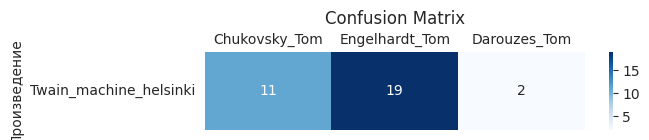

In [67]:
plot_confusion_matrix(result_table7['table'])

In [68]:
result_table7 = run_multi_book_attribution(
    train_authors=authors_TRAIN,
    test_books={
        'Twain_machine_google': 'Twain_machine_google',
    },
    preprocess_type='origcase_withpunct_withstop',
    n_slices=32,
    compressor='lzma',
    lvl=6
)

In [69]:
result_table7['table']


,Chukovsky_Tom,Engelhardt_Tom,Darouzes_Tom
Произведение,,,
Twain_machine_google,13,18,1


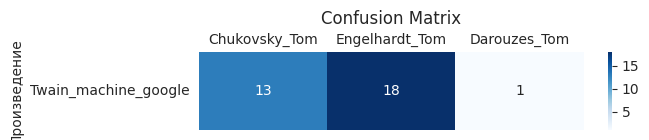

In [70]:
plot_confusion_matrix(result_table7['table'])

In [71]:
result_table7 = run_multi_book_attribution(
    train_authors=authors_TRAIN,
    test_books={
        'Twain_machine_yandex': 'Twain_machine_yandex',
    },
    preprocess_type='origcase_withpunct_withstop',
    n_slices=32,
    compressor='lzma',
    lvl=6
)

In [72]:
result_table7['table']


,Chukovsky_Tom,Engelhardt_Tom,Darouzes_Tom
Произведение,,,
Twain_machine_yandex,15,16,1


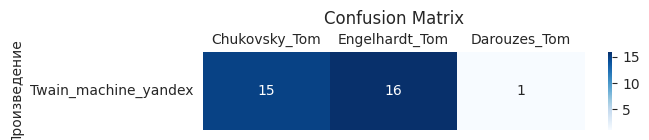

In [73]:
plot_confusion_matrix(result_table7['table'])

### Интерпретация

Переводчик с наименьшим средним NCD — наиболее "буквальный" (ближе к машинному переводу).
Переводчик с наибольшим NCD — наиболее "литературный" (дальше от машинного перевода).